# ESA Ground Station Scheduling Pipeline

This notebook starts after the data-wrangling pipeline has already created realistic candidate contact slots. The data-wrangling layers load satellite and ground-station data, compute visibility, apply operational assumptions, and export the weighted candidate-slot table used here.

The notebook then turns those candidate slots into an optimization problem: it validates the inputs, builds the conflict graph, decomposes the graph into independent and QPU-sized subproblems, constructs terminal QUBOs, and compares annealing-style results against classical references. The final reconstruction can be fully exact, or a feasible hybrid result with conservative bounds if any component cannot be exactly decomposed within the configured limits.


## Imports

The main pipeline now consumes already-discretized realistic candidate slots. Pandas is used only at the input boundary; the downstream notebook keeps using the existing project objects.


In [42]:
import importlib
import math

from itertools import combinations
from pathlib import Path
from typing import Dict

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

import sys, os
sys.path.insert(0, os.path.join('..', 'src'))
import candidate_slot_data_model
import raw_visibility_interval_data_model
importlib.reload(candidate_slot_data_model)
importlib.reload(raw_visibility_interval_data_model)

from candidate_slot_data_model import Antenna, CandidateSlot, GroundStation, Satellite
from raw_visibility_interval_data_model import SchedulingHorizon


## Realistic Candidate-Slot Input

The realistic data-generation pipeline replaces the old random raw-visibility load and notebook discretization phases. Layer E already outputs candidate slots, so this notebook does not run the old `RawVisibilityInterval -> CandidateSlot` discretizer again.

Choose one Layer E output below: the full weighted table, or one of the small/medium/dense instances.


In [43]:
REALISTIC_SLOT_DATASET_PATH = PROJECT_ROOT / "data" / "dataset" / "starlink" / "starlink_scheduling_slots_weighted.csv"
# Other useful choices:
# REALISTIC_SLOT_DATASET_PATH = Path("satellite-antenna-data/add-weight-data/starlink_scheduling_instance_small.csv")
# REALISTIC_SLOT_DATASET_PATH = Path("satellite-antenna-data/add-weight-data/starlink_scheduling_instance_medium.csv")
# REALISTIC_SLOT_DATASET_PATH = Path("satellite-antenna-data/add-weight-data/starlink_scheduling_instance_dense.csv")


def load_realistic_candidate_slot_rows(csv_path: Path) -> pd.DataFrame:
    """Load candidate slots generated by realistic data Layer E.

    Parameters
    ----------
    csv_path:
        Path to a Layer E candidate-slot CSV.

    Returns
    -------
    pandas.DataFrame
        Candidate-slot rows with all fields needed to build adapter objects.
    """
    if not csv_path.exists():
        raise FileNotFoundError(f"Missing realistic candidate-slot dataset: {csv_path}")

    rows = pd.read_csv(csv_path)
    required_columns = {
        "slot_id",
        "source_interval_id",
        "satellite_id",
        "antenna_id",
        "station_id",
        "station_name",
        "start_time_hours",
        "end_time_hours",
        "priority",
        "urgency",
        "weight",
        "reconfiguration_time_hours",
    }
    missing_columns = required_columns - set(rows.columns)
    if missing_columns:
        raise ValueError(f"Layer E dataset is missing required columns: {sorted(missing_columns)}")

    return rows


realistic_slot_rows = load_realistic_candidate_slot_rows(REALISTIC_SLOT_DATASET_PATH)

print(f"Loaded {len(realistic_slot_rows)} realistic candidate slots from {REALISTIC_SLOT_DATASET_PATH}.")
print(f"Unique parent windows: {realistic_slot_rows['source_interval_id'].nunique()}")
print(f"Unique satellites: {realistic_slot_rows['satellite_id'].nunique()}")
print(f"Unique antennas: {realistic_slot_rows['antenna_id'].nunique()}")
print(f"Unique stations: {realistic_slot_rows['station_id'].nunique()}")
realistic_slot_rows.head()


Loaded 2556 realistic candidate slots from ..\data\dataset\starlink\starlink_scheduling_slots_weighted.csv.
Unique parent windows: 2005
Unique satellites: 95
Unique antennas: 50
Unique stations: 50


,slot_id,parent_window_id,source_interval_id,satellite_name,satellite_id,norad_id,antenna_id,station_id,station_name,start_time,...,duration_norm,urgency_norm,elevation_norm,weight,scenario_tag,priority_mode,urgency_mode,weight_scope,min_contact_duration_seconds,discretization_step_seconds
0,SLOT_000001,VIS_000001,VIS_000001,STARLINK-1296,45412,45412,ANT_GATEWAY_0001,GATEWAY_0001,"Adelanto, CA",2026-05-31T00:00:00+00:00,...,0.750,1.0,0.629467,56.295,starlink_realistic_discretized_full,satellite_stable_with_pass_quality,earlier_slots_more_urgent,parent_visibility_window,300,120
1,SLOT_000002,VIS_000007,VIS_000007,STARLINK-1269,45197,45197,ANT_GATEWAY_0004,GATEWAY_0004,"Akron, OH",2026-05-31T00:00:00+00:00,...,0.625,1.0,0.367922,39.304,starlink_realistic_discretized_full,satellite_stable_with_pass_quality,earlier_slots_more_urgent,parent_visibility_window,300,120
2,SLOT_000003,VIS_000013,VIS_000013,STARLINK-1263,45405,45405,ANT_GATEWAY_0005,GATEWAY_0005,"Alfouvar de Cima, Portugal",2026-05-31T00:00:00+00:00,...,0.625,1.0,0.590911,52.784,starlink_realistic_discretized_full,satellite_stable_with_pass_quality,earlier_slots_more_urgent,parent_visibility_window,300,120
3,SLOT_000004,VIS_000017,VIS_000017,STARLINK-1269,45197,45197,ANT_GATEWAY_0007,GATEWAY_0007,"Anderson, SC",2026-05-31T00:00:00+00:00,...,0.750,1.0,0.909956,59.100,starlink_realistic_discretized_full,satellite_stable_with_pass_quality,earlier_slots_more_urgent,parent_visibility_window,300,120
4,SLOT_000005,VIS_000018,VIS_000018,STARLINK-1350,45535,45535,ANT_GATEWAY_0007,GATEWAY_0007,"Anderson, SC",2026-05-31T00:00:00+00:00,...,0.625,1.0,0.299289,83.618,starlink_realistic_discretized_full,satellite_stable_with_pass_quality,earlier_slots_more_urgent,parent_visibility_window,300,120


## Realistic Input Validation Checkpoint

This cell confirms that the Layer E candidate-slot CSV is present and has the fields needed to build the existing project objects.


In [44]:
assert REALISTIC_SLOT_DATASET_PATH.exists()
assert len(realistic_slot_rows) > 0
assert realistic_slot_rows["slot_id"].is_unique
assert realistic_slot_rows["end_time_hours"].gt(realistic_slot_rows["start_time_hours"]).all()
assert realistic_slot_rows["weight"].ge(0).all()

print("Realistic input validation passed: Layer E candidate slots loaded correctly.")


Realistic input validation passed: Layer E candidate slots loaded correctly.


## Adapter Object Creation

The downstream notebook still expects `GroundStation`, `Satellite`, `Antenna`, and `CandidateSlot` objects. This adapter creates those objects from the Layer E table with minimal transformation.

Layer E already filtered blackout-overlapping windows and generated candidate slots. Therefore, the compatibility blackout list is empty, and each antenna is considered available across the selected dataset horizon.


In [45]:
def intervals_overlap(first_start: float, first_end: float, second_start: float, second_end: float) -> bool:
    """Return True when two half-open time intervals overlap."""
    return first_start < second_end and second_start < first_end


def build_realistic_adapter_objects(slot_rows: pd.DataFrame) -> tuple[
    list[CandidateSlot],
    dict[str, Satellite],
    dict[str, GroundStation],
    dict[str, Antenna],
]:
    """Build existing pipeline objects from Layer E candidate-slot rows.

    Parameters
    ----------
    slot_rows:
        Layer E candidate-slot table.

    Returns
    -------
    tuple
        Candidate slots, satellites, ground stations, and antennas keyed by ID.
    """
    ground_stations_by_id = {
        station_id: GroundStation(id=station_id, name=group["station_name"].iloc[0])
        for station_id, group in slot_rows.groupby("station_id", sort=True)
    }
    satellites_by_id = {
        str(satellite_id): Satellite(id=str(satellite_id))
        for satellite_id in sorted(slot_rows["satellite_id"].astype(str).unique())
    }
    antennas_by_id = {}
    for antenna_id, group in slot_rows.groupby("antenna_id", sort=True):
        station_id = group["station_id"].iloc[0]
        antennas_by_id[antenna_id] = Antenna(
            id=antenna_id,
            description=f"Realistic gateway antenna {antenna_id}",
            station=ground_stations_by_id[station_id],
            reconfiguration_time=float(group["reconfiguration_time_hours"].iloc[0]),
        )

    candidate_slots = []
    for row in slot_rows.itertuples(index=False):
        satellite_id = str(row.satellite_id)
        slot = CandidateSlot(
            slot_id=row.slot_id,
            source_interval_id=row.source_interval_id,
            satellite=satellites_by_id[satellite_id],
            antenna=antennas_by_id[row.antenna_id],
            start_time=float(row.start_time_hours),
            end_time=float(row.end_time_hours),
            priority=float(row.priority),
            urgency=float(row.urgency),
        )
        slot.weight = float(row.weight)
        candidate_slots.append(slot)

    return candidate_slots, satellites_by_id, ground_stations_by_id, antennas_by_id


phase_2_slots, satellites_by_id, ground_stations_by_id, antennas_by_id = build_realistic_adapter_objects(realistic_slot_rows)

horizon_start = math.floor(min(slot.start_time for slot in phase_2_slots))
horizon_end = math.ceil(max(slot.end_time for slot in phase_2_slots))
SCHEDULING_HORIZON = SchedulingHorizon(start_time=float(horizon_start), end_time=float(horizon_end))

phase_2_antenna_availability = {
    antenna_id: (SCHEDULING_HORIZON.start_time, SCHEDULING_HORIZON.end_time)
    for antenna_id in antennas_by_id
}
phase_2_blackout_intervals: list[tuple[float, float]] = []
phase_2_rejections: list[dict[str, str]] = []
PHASE_3_MIN_DURATION = max(0.0, min(slot.duration for slot in phase_2_slots) - 1e-9)

print(f"Adapter candidate slots: {len(phase_2_slots)}")
print(f"Scheduling horizon: {SCHEDULING_HORIZON.start_time}-{SCHEDULING_HORIZON.end_time} hours")
print(f"Antennas: {len(antennas_by_id)}")
print(f"Stations: {len(ground_stations_by_id)}")
print(f"Satellites: {len(satellites_by_id)}")
print(f"Phase 3 minimum duration guard: {PHASE_3_MIN_DURATION:.6f} hours")
print("\nFirst five adapter candidate slots:")
for slot in phase_2_slots[:5]:
    print(slot.as_dict())


Adapter candidate slots: 2556
Scheduling horizon: 0.0-4.0 hours
Antennas: 50
Stations: 50
Satellites: 95
Phase 3 minimum duration guard: 0.083333 hours

First five adapter candidate slots:
{'slot_id': 'SLOT_000001', 'source_interval_id': 'VIS_000001', 'satellite_id': '45412', 'antenna_id': 'ANT_GATEWAY_0001', 'station_id': 'GATEWAY_0001', 'reconfiguration_time': 0.05, 'start_time': 0.0, 'end_time': 0.0833333333333333, 'duration': 0.0833333333333333, 'priority': 2.0, 'urgency': 5.0, 'weight': 56.295}
{'slot_id': 'SLOT_000002', 'source_interval_id': 'VIS_000007', 'satellite_id': '45197', 'antenna_id': 'ANT_GATEWAY_0004', 'station_id': 'GATEWAY_0004', 'reconfiguration_time': 0.05, 'start_time': 0.0, 'end_time': 0.0833333333333333, 'duration': 0.0833333333333333, 'priority': 1.0, 'urgency': 5.0, 'weight': 39.304}
{'slot_id': 'SLOT_000003', 'source_interval_id': 'VIS_000013', 'satellite_id': '45405', 'antenna_id': 'ANT_GATEWAY_0005', 'station_id': 'GATEWAY_0005', 'reconfiguration_time': 0.0

## Adapter Validation Checkpoint

This cell confirms that the Layer E candidate slots were converted into the object model expected by the original Phase 3+ notebook logic.


In [46]:
assert len(phase_2_slots) == len(realistic_slot_rows)
assert len(phase_2_slots) > 0
assert all(slot.weight >= 0 for slot in phase_2_slots)
assert all(slot.duration > 0 for slot in phase_2_slots)
assert all(slot.antenna_id in phase_2_antenna_availability for slot in phase_2_slots)
assert SCHEDULING_HORIZON.start_time <= min(slot.start_time for slot in phase_2_slots)
assert SCHEDULING_HORIZON.end_time >= max(slot.end_time for slot in phase_2_slots)

print("Adapter validation passed: realistic candidate slots are ready for Phase 3 reductions.")


Adapter validation passed: realistic candidate slots are ready for Phase 3 reductions.


## Legacy Discretization Removed

The previous notebook implementation defined a raw-window discretizer here. That logic now lives in the realistic data-generation Layer E notebook, which emits candidate slots directly. The remaining cells continue from the `phase_2_slots` compatibility variable created above.


## Phase 2 Replacement Summary

Old Phases 1 and 2 are replaced by the realistic data-generation pipeline. In this notebook, `phase_2_slots` now means: candidate slots loaded from Layer E and converted into adapter objects.


Layer E source file currently selected:

`satellite-antenna-data\add-weight-data\starlink_scheduling_slots_weighted.csv`

Downstream phases can continue using `phase_2_slots`, `SCHEDULING_HORIZON`, `phase_2_antenna_availability`, and `phase_2_blackout_intervals` without needing to know whether the slots came from the old synthetic generator or the new realistic data pipeline.


## Phase 2 Compatibility Validation

The object-adapter boundary preserves the variables expected by the original Phase 3+ notebook.


In [47]:
assert len(phase_2_slots) == len(realistic_slot_rows)
assert phase_2_rejections == []
assert phase_2_blackout_intervals == []
assert all(slot.duration >= PHASE_3_MIN_DURATION for slot in phase_2_slots)

print("Phase 2 compatibility validation passed: realistic candidate slots replace old raw-window discretization.")


Phase 2 compatibility validation passed: realistic candidate slots replace old raw-window discretization.


## Phase 3: Classical Reduction Core

This phase implements the first safe reduction pipeline. It has two parts:

- **Step 3A: constraint propagation**, which removes candidate slots that are deterministically infeasible.
- **Step 3B: safe structural reductions**, which remove exact duplicates and locally dominated slots.

No heuristic reductions are implemented in this phase.


## Step 3A: Constraint Propagation

The checks below are intentionally explicit. Each helper returns a Boolean and a short reason string so the reduction pipeline can report exactly why a slot was removed.


In [48]:
def check_data_consistency(slot: CandidateSlot, horizon_start: float, horizon_end: float) -> tuple[bool, str]:
    """Check basic slot identifiers, numeric values, and horizon membership."""
    required_ids = [slot.slot_id, slot.satellite_id, slot.antenna_id, slot.station_id]
    if any(not value for value in required_ids):
        return False, "missing identifier"

    numeric_values = [slot.start_time, slot.end_time, slot.priority, slot.urgency, slot.weight]
    if any(not math.isfinite(value) for value in numeric_values):
        return False, "non-finite numeric value"

    if slot.priority < 0 or slot.urgency < 0:
        return False, "negative scoring input"

    if slot.end_time <= slot.start_time:
        return False, "invalid time order"

    if slot.start_time < horizon_start or slot.end_time > horizon_end:
        return False, "outside scheduling horizon"

    return True, "ok"


def check_availability_consistency(
    slot: CandidateSlot,
    antenna_availability: Dict[str, tuple[float, float]],
) -> tuple[bool, str]:
    """Check that a slot lies inside its antenna availability interval."""
    if slot.antenna_id not in antenna_availability:
        return False, "unknown antenna availability"

    available_start, available_end = antenna_availability[slot.antenna_id]
    if slot.start_time < available_start or slot.end_time > available_end:
        return False, "outside antenna availability"

    return True, "ok"


def check_blackout_consistency(
    slot: CandidateSlot,
    blackout_intervals: list[tuple[float, float]],
) -> tuple[bool, str]:
    """Check that a slot does not overlap any blackout interval."""
    for blackout_start, blackout_end in blackout_intervals:
        if intervals_overlap(slot.start_time, slot.end_time, blackout_start, blackout_end):
            return False, "overlaps blackout interval"

    return True, "ok"


def check_duration_consistency(
    slot: CandidateSlot,
    min_duration: float,
    max_duration: float | None = None,
) -> tuple[bool, str]:
    """Check that a slot duration lies within the allowed duration limits."""
    if slot.duration < min_duration:
        return False, "below minimum duration"

    if max_duration is not None and slot.duration > max_duration:
        return False, "above maximum duration"

    return True, "ok"


def check_local_transition_consistency(
    slot: CandidateSlot,
    fixed_contacts: list[CandidateSlot],
) -> tuple[bool, str]:
    """Check that a slot leaves antenna-specific transition time around fixed contacts."""
    for fixed_contact in fixed_contacts:
        if slot.antenna_id != fixed_contact.antenna_id:
            continue

        reconfiguration_time = max(
            slot.antenna.reconfiguration_time,
            fixed_contact.antenna.reconfiguration_time,
        )

        # Expanding the fixed contact captures direct overlap and setup time.
        blocked_start = fixed_contact.start_time - reconfiguration_time
        blocked_end = fixed_contact.end_time + reconfiguration_time
        if intervals_overlap(slot.start_time, slot.end_time, blocked_start, blocked_end):
            return False, "conflicts with fixed contact transition time"

    return True, "ok"


def apply_constraint_propagation(
    slots: list[CandidateSlot],
    horizon_start: float,
    horizon_end: float,
    antenna_availability: Dict[str, tuple[float, float]],
    blackout_intervals: list[tuple[float, float]],
    min_duration: float,
    max_duration: float | None = None,
    fixed_contacts: list[CandidateSlot] | None = None,
) -> tuple[list[CandidateSlot], list[Dict[str, str]]]:
    """Remove candidate slots that deterministically violate hard constraints."""
    fixed_contacts = fixed_contacts or []
    kept_slots = []
    removed_slots = []

    for slot in slots:
        checks = [
            check_data_consistency(slot, horizon_start, horizon_end),
            check_availability_consistency(slot, antenna_availability),
            check_blackout_consistency(slot, blackout_intervals),
            check_duration_consistency(slot, min_duration, max_duration),
            check_local_transition_consistency(slot, fixed_contacts),
        ]

        failed_check = next((check for check in checks if not check[0]), None)
        if failed_check is None:
            kept_slots.append(slot)
        else:
            removed_slots.append({"slot_id": slot.slot_id, "reason": failed_check[1]})

    return kept_slots, removed_slots


## Step 3B: Safe Structural Reductions

Two safe structural reductions are implemented here:

- **Duplicate removal:** slots with the same satellite, antenna, station, and time interval are duplicates. The highest-weight copy is kept.
- **Strong local dominance:** for the same satellite, antenna, and station, a shorter slot that is fully contained in a longer slot and has at least the same weight dominates the longer slot. The shorter slot is no worse in value and uses no more antenna time.


In [49]:
def duplicate_key(slot: CandidateSlot) -> tuple[str, str, str, float, float]:
    """Return the key used to identify exact duplicate candidate slots."""
    return (slot.satellite_id, slot.antenna_id, slot.station_id, slot.start_time, slot.end_time)


def remove_duplicate_slots(slots: list[CandidateSlot]) -> tuple[list[CandidateSlot], list[Dict[str, str]]]:
    """Remove exact duplicate slots, keeping the highest-weight copy."""
    best_slot_by_key = {}
    removed_slots = []

    for slot in slots:
        key = duplicate_key(slot)
        current_best = best_slot_by_key.get(key)

        if current_best is None:
            best_slot_by_key[key] = slot
        elif slot.weight > current_best.weight:
            removed_slots.append({"slot_id": current_best.slot_id, "reason": f"duplicate of {slot.slot_id} with lower weight"})
            best_slot_by_key[key] = slot
        else:
            removed_slots.append({"slot_id": slot.slot_id, "reason": f"duplicate of {current_best.slot_id} with lower or equal weight"})

    return list(best_slot_by_key.values()), removed_slots


def slot_contains(outer_slot: CandidateSlot, inner_slot: CandidateSlot) -> bool:
    """Return True when `outer_slot` fully contains `inner_slot` in time."""
    return outer_slot.start_time <= inner_slot.start_time and outer_slot.end_time >= inner_slot.end_time


def remove_strongly_dominated_slots(slots: list[CandidateSlot]) -> tuple[list[CandidateSlot], list[Dict[str, str]]]:
    """Remove locally dominated slots using a conservative containment rule."""
    dominated_slot_ids = set()
    removed_slots = []

    for possible_dominator in slots:
        for possible_dominated in slots:
            if possible_dominator.slot_id == possible_dominated.slot_id:
                continue

            same_local_resource = (
                possible_dominator.satellite_id == possible_dominated.satellite_id
                and possible_dominator.antenna_id == possible_dominated.antenna_id
                and possible_dominator.station_id == possible_dominated.station_id
            )
            if not same_local_resource:
                continue

            dominator_uses_no_more_time = slot_contains(possible_dominated, possible_dominator)
            dominator_is_no_worse = possible_dominator.weight >= possible_dominated.weight

            if dominator_uses_no_more_time and dominator_is_no_worse:
                if possible_dominated.slot_id not in dominated_slot_ids:
                    dominated_slot_ids.add(possible_dominated.slot_id)
                    removed_slots.append({"slot_id": possible_dominated.slot_id, "reason": f"dominated by contained slot {possible_dominator.slot_id}"})

    kept_slots = [slot for slot in slots if slot.slot_id not in dominated_slot_ids]
    return kept_slots, removed_slots


def run_safe_reduction_pipeline(
    slots: list[CandidateSlot],
    horizon_start: float,
    horizon_end: float,
    antenna_availability: Dict[str, tuple[float, float]],
    blackout_intervals: list[tuple[float, float]],
    min_duration: float,
    max_duration: float | None = None,
    fixed_contacts: list[CandidateSlot] | None = None,
) -> tuple[list[CandidateSlot], Dict[str, object]]:
    """Run Phase 3A and Phase 3B safe reductions in sequence."""
    after_constraint_propagation, constraint_removals = apply_constraint_propagation(
        slots=slots,
        horizon_start=horizon_start,
        horizon_end=horizon_end,
        antenna_availability=antenna_availability,
        blackout_intervals=blackout_intervals,
        min_duration=min_duration,
        max_duration=max_duration,
        fixed_contacts=fixed_contacts,
        )
    after_duplicate_removal, duplicate_removals = remove_duplicate_slots(after_constraint_propagation)
    final_slots, dominance_removals = remove_strongly_dominated_slots(after_duplicate_removal)

    report = {
        "input_size": len(slots),
        "after_step_3a_size": len(after_constraint_propagation),
        "after_duplicate_removal_size": len(after_duplicate_removal),
        "final_size": len(final_slots),
        "constraint_removals": constraint_removals,
        "duplicate_removals": duplicate_removals,
        "dominance_removals": dominance_removals,
    }
    return final_slots, report


## Phase 3 Realistic Dataset Reduction

The safe reduction pipeline now runs on the candidate slots loaded from realistic Layer E. Layer D/E already handled operational filtering and discretization; Phase 3 remains a guardrail for data consistency, duplicate removal, and structural reductions.


In [50]:
phase_3_slots = phase_2_slots
phase_3_antenna_availability = phase_2_antenna_availability
phase_3_blackout_intervals = phase_2_blackout_intervals
phase_3_fixed_contacts = []

phase_3_reduced_slots, phase_3_report = run_safe_reduction_pipeline(
    slots=phase_3_slots,
    horizon_start=SCHEDULING_HORIZON.start_time,
    horizon_end=SCHEDULING_HORIZON.end_time,
    antenna_availability=phase_3_antenna_availability,
    blackout_intervals=phase_3_blackout_intervals,
    min_duration=PHASE_3_MIN_DURATION,
    fixed_contacts=phase_3_fixed_contacts,
)

print("Phase 3 reduction sizes:")
print(f"Input size (Layer E candidate slots): {phase_3_report['input_size']}")
print(f"After Step 3A: {phase_3_report['after_step_3a_size']}")
print(f"After duplicate removal: {phase_3_report['after_duplicate_removal_size']}")
print(f"Final size: {phase_3_report['final_size']}")

print("\nConstraint removals:")
for removal in phase_3_report["constraint_removals"][:10]:
    print(removal)

print("\nDuplicate removals:")
for removal in phase_3_report["duplicate_removals"][:10]:
    print(removal)

print("\nDominance removals:")
for removal in phase_3_report["dominance_removals"][:10]:
    print(removal)

print("\nFirst five reduced slots:")
for slot in phase_3_reduced_slots[:5]:
    print(slot.as_dict())


Phase 3 reduction sizes:
Input size (Layer E candidate slots): 2556
After Step 3A: 2556
After duplicate removal: 2556
Final size: 2556

Constraint removals:

Duplicate removals:

Dominance removals:

First five reduced slots:
{'slot_id': 'SLOT_000001', 'source_interval_id': 'VIS_000001', 'satellite_id': '45412', 'antenna_id': 'ANT_GATEWAY_0001', 'station_id': 'GATEWAY_0001', 'reconfiguration_time': 0.05, 'start_time': 0.0, 'end_time': 0.0833333333333333, 'duration': 0.0833333333333333, 'priority': 2.0, 'urgency': 5.0, 'weight': 56.295}
{'slot_id': 'SLOT_000002', 'source_interval_id': 'VIS_000007', 'satellite_id': '45197', 'antenna_id': 'ANT_GATEWAY_0004', 'station_id': 'GATEWAY_0004', 'reconfiguration_time': 0.05, 'start_time': 0.0, 'end_time': 0.0833333333333333, 'duration': 0.0833333333333333, 'priority': 1.0, 'urgency': 5.0, 'weight': 39.304}
{'slot_id': 'SLOT_000003', 'source_interval_id': 'VIS_000013', 'satellite_id': '45405', 'antenna_id': 'ANT_GATEWAY_0005', 'station_id': 'GATEW

## Phase 3 Validation Checkpoint

This cell checks that safe reductions run correctly on the realistic candidate-slot adapter objects.


In [51]:
assert phase_3_report["input_size"] == len(phase_2_slots)
assert phase_3_report["after_step_3a_size"] <= phase_3_report["input_size"]
assert phase_3_report["after_duplicate_removal_size"] <= phase_3_report["after_step_3a_size"]
assert phase_3_report["final_size"] <= phase_3_report["after_duplicate_removal_size"]
assert len(phase_3_reduced_slots) == phase_3_report["final_size"]
assert all(slot.duration >= PHASE_3_MIN_DURATION for slot in phase_3_reduced_slots)

print("Phase 3 validation passed: safe reductions run on realistic candidate slots.")


Phase 3 validation passed: safe reductions run on realistic candidate slots.


## Phase 4: First Heuristic Reduction

This phase adds the first heuristic reduction: **top-k per satellite**. Unlike the Phase 3 reductions, this step is not guaranteed to preserve the exact optimum. It is useful when a benchmark instance is too large and we want a controlled way to keep only the strongest candidate slots for each satellite.

The heuristic is applied only when explicitly requested.


## Top-k Per Satellite

The function groups slots by satellite, sorts each group by descending weight, and keeps the first `k` slots per satellite. Ties are broken by earlier start time and then by slot id for deterministic output.


In [52]:
def keep_top_k_per_satellite(slots: list[CandidateSlot], k: int) -> tuple[list[CandidateSlot], list[Dict[str, str]]]:
    """Keep at most the top `k` candidate slots for each satellite.

    Slots are ranked within each satellite by descending weight. Earlier start
    time and slot id are used as deterministic tie breakers.
    """
    if k <= 0:
        raise ValueError("k must be a positive integer.")

    slots_by_satellite = {}
    for slot in slots:
        slots_by_satellite.setdefault(slot.satellite_id, []).append(slot)

    kept_slots = []
    removed_slots = []

    for satellite_id in sorted(slots_by_satellite):
        satellite_slots = slots_by_satellite[satellite_id]
        ranked_slots = sorted(
            satellite_slots,
            key=lambda slot: (-slot.weight, slot.start_time, slot.slot_id),
        )

        kept_slots.extend(ranked_slots[:k])
        for removed_slot in ranked_slots[k:]:
            removed_slots.append(
                {
                    "slot_id": removed_slot.slot_id,
                    "satellite_id": removed_slot.satellite_id,
                    "reason": f"outside top {k} for satellite {removed_slot.satellite_id}",
                }
            )

    return kept_slots, removed_slots


def run_reduction_pipeline_with_optional_top_k(
    slots: list[CandidateSlot],
    horizon_start: float,
    horizon_end: float,
    antenna_availability: Dict[str, tuple[float, float]],
    blackout_intervals: list[tuple[float, float]],
    min_duration: float,
    max_duration: float | None = None,
    fixed_contacts: list[CandidateSlot] | None = None,
    top_k_per_satellite: int | None = None,
) -> tuple[list[CandidateSlot], Dict[str, object]]:
    """Run safe reductions and optionally apply top-k per satellite."""
    reduced_slots, report = run_safe_reduction_pipeline(
        slots=slots,
        horizon_start=horizon_start,
        horizon_end=horizon_end,
        antenna_availability=antenna_availability,
        blackout_intervals=blackout_intervals,
        min_duration=min_duration,
        max_duration=max_duration,
        fixed_contacts=fixed_contacts,
        )

    report["top_k_per_satellite"] = top_k_per_satellite
    report["top_k_removals"] = []

    if top_k_per_satellite is not None:
        reduced_slots, top_k_removals = keep_top_k_per_satellite(
            slots=reduced_slots,
            k=top_k_per_satellite,
        )
        report["top_k_removals"] = top_k_removals

    report["after_optional_top_k_size"] = len(reduced_slots)
    return reduced_slots, report


## Phase 4 Shared Dataset Top-k Example

The top-k heuristic now runs on the Phase 3 reduced dataset. This keeps the shared data flowing into the optional heuristic reduction step.


In [53]:
phase_4_slots = phase_3_reduced_slots

for k in [1, 3]:
    top_k_slots, top_k_removals = keep_top_k_per_satellite(phase_4_slots, k=k)

    print(f"Top-{k} per satellite keeps {len(top_k_slots)} slots.")
    print(f"Top-{k} removals: {len(top_k_removals)}")
    print("First five kept slots:")
    for slot in top_k_slots[:5]:
        print({"slot_id": slot.slot_id, "satellite_id": slot.satellite_id, "weight": slot.weight})
    print()


Top-1 per satellite keeps 95 slots.
Top-1 removals: 2461
First five kept slots:
{'slot_id': 'SLOT_000452', 'satellite_id': '44714', 'weight': 78.857}
{'slot_id': 'SLOT_000453', 'satellite_id': '44718', 'weight': 66.72}
{'slot_id': 'SLOT_000826', 'satellite_id': '44723', 'weight': 81.239}
{'slot_id': 'SLOT_000294', 'satellite_id': '44725', 'weight': 84.476}
{'slot_id': 'SLOT_000463', 'satellite_id': '44741', 'weight': 86.668}

Top-3 per satellite keeps 266 slots.
Top-3 removals: 2290
First five kept slots:
{'slot_id': 'SLOT_000452', 'satellite_id': '44714', 'weight': 78.857}
{'slot_id': 'SLOT_000468', 'satellite_id': '44714', 'weight': 78.857}
{'slot_id': 'SLOT_000486', 'satellite_id': '44714', 'weight': 65.091}
{'slot_id': 'SLOT_000453', 'satellite_id': '44718', 'weight': 66.72}
{'slot_id': 'SLOT_000469', 'satellite_id': '44718', 'weight': 66.72}



## Optional Pipeline Integration Demo

The cell below controls whether the downstream pipeline uses the Phase 4 top-k heuristic. Set `PHASE_4_TOP_K_PER_SATELLITE = None` to bypass the heuristic and pass the Phase 3 safely reduced slots into Phase 5. Set it back to `3` to restore the previous top-3 behavior.


In [54]:
PHASE_4_TOP_K_PER_SATELLITE = None
# Use PHASE_4_TOP_K_PER_SATELLITE = None to bypass the heuristic reduction.

phase_4_pipeline_slots, phase_4_pipeline_report = run_reduction_pipeline_with_optional_top_k(
    slots=phase_4_slots,
    horizon_start=SCHEDULING_HORIZON.start_time,
    horizon_end=SCHEDULING_HORIZON.end_time,
    antenna_availability=phase_3_antenna_availability,
    blackout_intervals=phase_3_blackout_intervals,
    min_duration=PHASE_3_MIN_DURATION,
    top_k_per_satellite=PHASE_4_TOP_K_PER_SATELLITE,
)

print("Phase 4 downstream candidate-set selection:")
print({"top_k_per_satellite": PHASE_4_TOP_K_PER_SATELLITE})
print(f"After safe reductions: {phase_4_pipeline_report['final_size']}")
print(f"After optional top-k: {phase_4_pipeline_report['after_optional_top_k_size']}")

for slot in phase_4_pipeline_slots[:10]:
    print({"slot_id": slot.slot_id, "satellite_id": slot.satellite_id, "weight": slot.weight})


Phase 4 downstream candidate-set selection:
{'top_k_per_satellite': None}
After safe reductions: 2556
After optional top-k: 2556
{'slot_id': 'SLOT_000001', 'satellite_id': '45412', 'weight': 56.295}
{'slot_id': 'SLOT_000002', 'satellite_id': '45197', 'weight': 39.304}
{'slot_id': 'SLOT_000003', 'satellite_id': '45405', 'weight': 52.784}
{'slot_id': 'SLOT_000004', 'satellite_id': '45197', 'weight': 59.1}
{'slot_id': 'SLOT_000005', 'satellite_id': '45535', 'weight': 83.618}
{'slot_id': 'SLOT_000006', 'satellite_id': '44768', 'weight': 41.29}
{'slot_id': 'SLOT_000007', 'satellite_id': '45412', 'weight': 49.276}
{'slot_id': 'SLOT_000008', 'satellite_id': '45412', 'weight': 54.903}
{'slot_id': 'SLOT_000009', 'satellite_id': '45197', 'weight': 38.788}
{'slot_id': 'SLOT_000010', 'satellite_id': '45197', 'weight': 56.96}


## Phase 4 Validation Checkpoint

This cell checks that top-k per satellite still works as a heuristic, and that the downstream pipeline either applies it or cleanly bypasses it depending on `PHASE_4_TOP_K_PER_SATELLITE`.


In [55]:
top_1_slots, top_1_removals = keep_top_k_per_satellite(phase_4_slots, k=1)
top_3_slots, top_3_removals = keep_top_k_per_satellite(phase_4_slots, k=3)

for slot_collection, k in [(top_1_slots, 1), (top_3_slots, 3)]:
    counts_by_satellite = {}
    for slot in slot_collection:
        counts_by_satellite[slot.satellite_id] = counts_by_satellite.get(slot.satellite_id, 0) + 1
    assert all(count <= k for count in counts_by_satellite.values())

assert phase_4_pipeline_report["top_k_per_satellite"] == PHASE_4_TOP_K_PER_SATELLITE
assert phase_4_pipeline_report["after_optional_top_k_size"] == len(phase_4_pipeline_slots)

if PHASE_4_TOP_K_PER_SATELLITE is None:
    assert phase_4_pipeline_report["after_optional_top_k_size"] == phase_4_pipeline_report["final_size"]
else:
    counts_by_satellite = {}
    for slot in phase_4_pipeline_slots:
        counts_by_satellite[slot.satellite_id] = counts_by_satellite.get(slot.satellite_id, 0) + 1
    assert all(count <= PHASE_4_TOP_K_PER_SATELLITE for count in counts_by_satellite.values())

print("Phase 4 validation passed: top-k can be applied or bypassed safely.")


Phase 4 validation passed: top-k can be applied or bypassed safely.


## Phase 5: Conflict Graph Construction

This phase builds the weighted conflict graph from a reduced candidate-slot set.

- A **node** represents one surviving `CandidateSlot`.
- A **node weight** is the slot's computed optimization value.
- An **edge** represents an incompatibility between two slots.

The implementation uses `networkx.Graph` so later phases can reuse standard graph operations directly.


## Edge Construction Rules

Phase 5 implements exactly two incompatibility rules:

1. **Same-antenna overlap conflict:** two slots on the same antenna overlap in time.
2. **Same-antenna reconfiguration-time conflict:** two non-overlapping slots on the same antenna are closer than the required reconfiguration time.


In [56]:
def same_source_interval_conflict(first_slot: CandidateSlot, second_slot: CandidateSlot) -> bool:
    """Return True when two slots are alternative placements of the same request."""
    return first_slot.source_interval_id == second_slot.source_interval_id


def same_antenna_overlap_conflict(first_slot: CandidateSlot, second_slot: CandidateSlot) -> bool:
    """Return True when two slots overlap on the same antenna."""
    if first_slot.antenna_id != second_slot.antenna_id:
        return False

    return intervals_overlap(
        first_slot.start_time,
        first_slot.end_time,
        second_slot.start_time,
        second_slot.end_time,
    )


def time_gap_between_non_overlapping_slots(first_slot: CandidateSlot, second_slot: CandidateSlot) -> float:
    """Return the time gap between two non-overlapping slots."""
    if first_slot.end_time <= second_slot.start_time:
        return second_slot.start_time - first_slot.end_time

    return first_slot.start_time - second_slot.end_time


def same_antenna_reconfiguration_conflict(
    first_slot: CandidateSlot,
    second_slot: CandidateSlot,
) -> bool:
    """Return True when same-antenna slots are too close in time."""
    if first_slot.antenna_id != second_slot.antenna_id:
        return False

    if same_antenna_overlap_conflict(first_slot, second_slot):
        return False

    gap = time_gap_between_non_overlapping_slots(first_slot, second_slot)
    required_gap = max(
        first_slot.antenna.reconfiguration_time,
        second_slot.antenna.reconfiguration_time,
    )
    return gap < required_gap


def build_conflict_graph(slots: list[CandidateSlot]) -> nx.Graph:
    """Build a conflict graph from reduced candidate slots."""
    graph = nx.Graph()

    for slot in slots:
        graph.add_node(
            slot.slot_id,
            slot=slot,
            weight=slot.weight,
            source_interval_id=slot.source_interval_id,
            satellite_id=slot.satellite_id,
            antenna_id=slot.antenna_id,
            station_id=slot.station_id,
            reconfiguration_time=slot.antenna.reconfiguration_time,
            start_time=slot.start_time,
            end_time=slot.end_time,
        )

    for first_slot, second_slot in combinations(slots, 2):
        if same_source_interval_conflict(first_slot, second_slot):
            graph.add_edge(
                first_slot.slot_id,
                second_slot.slot_id,
                reason="same communication request",
                source_interval_id=first_slot.source_interval_id,
            )
        elif same_antenna_overlap_conflict(first_slot, second_slot):
            graph.add_edge(first_slot.slot_id, second_slot.slot_id, reason="same-antenna overlap")
        elif same_antenna_reconfiguration_conflict(first_slot, second_slot):
            graph.add_edge(
                first_slot.slot_id,
                second_slot.slot_id,
                reason="same-antenna reconfiguration time",
                reconfiguration_time=max(
                    first_slot.antenna.reconfiguration_time,
                    second_slot.antenna.reconfiguration_time,
                ),
            )

    return graph


## Graph Diagnostics

The diagnostics summarize the graph size and structure. Connected components are computed here only as a diagnostic; later phases may use components more directly for QPU subproblem selection.


In [57]:
def connected_components(graph: nx.Graph) -> list[set[str]]:
    """Return connected components of the conflict graph."""
    return [set(component) for component in nx.connected_components(graph)]


def graph_diagnostics(graph: nx.Graph) -> Dict[str, object]:
    """Compute basic diagnostics for a conflict graph."""
    node_count = graph.number_of_nodes()
    edge_count = graph.number_of_edges()
    average_degree = 0.0 if node_count == 0 else sum(dict(graph.degree()).values()) / node_count
    density = nx.density(graph)
    components = connected_components(graph)

    return {
        "node_count": node_count,
        "edge_count": edge_count,
        "average_degree": average_degree,
        "density": density,
        "connected_components": components,
        "component_count": len(components),
    }


def print_conflict_graph(graph: nx.Graph) -> None:
    """Print nodes, edges, and diagnostics for readable notebook inspection."""
    diagnostics = graph_diagnostics(graph)

    print("Nodes:")
    for slot_id in sorted(graph.nodes):
        slot = graph.nodes[slot_id]["slot"]
        print({"slot_id": slot_id, "source_interval_id": slot.source_interval_id, "antenna_id": slot.antenna_id, "start_time": slot.start_time, "end_time": slot.end_time, "weight": slot.weight})

    print("\nEdges:")
    for first_slot_id, second_slot_id, edge_data in sorted(graph.edges(data=True)):
        edge_summary = {"edge": (first_slot_id, second_slot_id), "reason": edge_data["reason"]}
        if "source_interval_id" in edge_data:
            edge_summary["source_interval_id"] = edge_data["source_interval_id"]
        print(edge_summary)

    print("\nDiagnostics:")
    print({"node_count": diagnostics["node_count"], "edge_count": diagnostics["edge_count"]})
    print({"average_degree": diagnostics["average_degree"], "density": diagnostics["density"]})
    print({"component_count": diagnostics["component_count"], "connected_components": diagnostics["connected_components"]})


## Phase 5 Shared Dataset Conflict Graph

The conflict graph is built from the Phase 4 candidate set. Nodes are surviving candidate slots, and edges are same-antenna timing conflicts.


In [58]:
phase_5_slots = phase_4_pipeline_slots

phase_5_graph = build_conflict_graph(phase_5_slots)
print_conflict_graph(phase_5_graph)


Nodes:
{'slot_id': 'SLOT_000001', 'source_interval_id': 'VIS_000001', 'antenna_id': 'ANT_GATEWAY_0001', 'start_time': 0.0, 'end_time': 0.0833333333333333, 'weight': 56.295}
{'slot_id': 'SLOT_000002', 'source_interval_id': 'VIS_000007', 'antenna_id': 'ANT_GATEWAY_0004', 'start_time': 0.0, 'end_time': 0.0833333333333333, 'weight': 39.304}
{'slot_id': 'SLOT_000003', 'source_interval_id': 'VIS_000013', 'antenna_id': 'ANT_GATEWAY_0005', 'start_time': 0.0, 'end_time': 0.0833333333333333, 'weight': 52.784}
{'slot_id': 'SLOT_000004', 'source_interval_id': 'VIS_000017', 'antenna_id': 'ANT_GATEWAY_0007', 'start_time': 0.0, 'end_time': 0.0833333333333333, 'weight': 59.1}
{'slot_id': 'SLOT_000005', 'source_interval_id': 'VIS_000018', 'antenna_id': 'ANT_GATEWAY_0007', 'start_time': 0.0, 'end_time': 0.0833333333333333, 'weight': 83.618}
{'slot_id': 'SLOT_000006', 'source_interval_id': 'VIS_000019', 'antenna_id': 'ANT_GATEWAY_0008', 'start_time': 0.0, 'end_time': 0.0833333333333333, 'weight': 41.29}


## Phase 5 Graph Visualization

The graph can also be inspected visually. Node colors are assigned dynamically from the real antenna identifiers present in the graph, because antenna resources drive overlap and reconfiguration conflicts. Node labels stay compact by showing slot IDs; the legend maps colors to real antenna IDs.


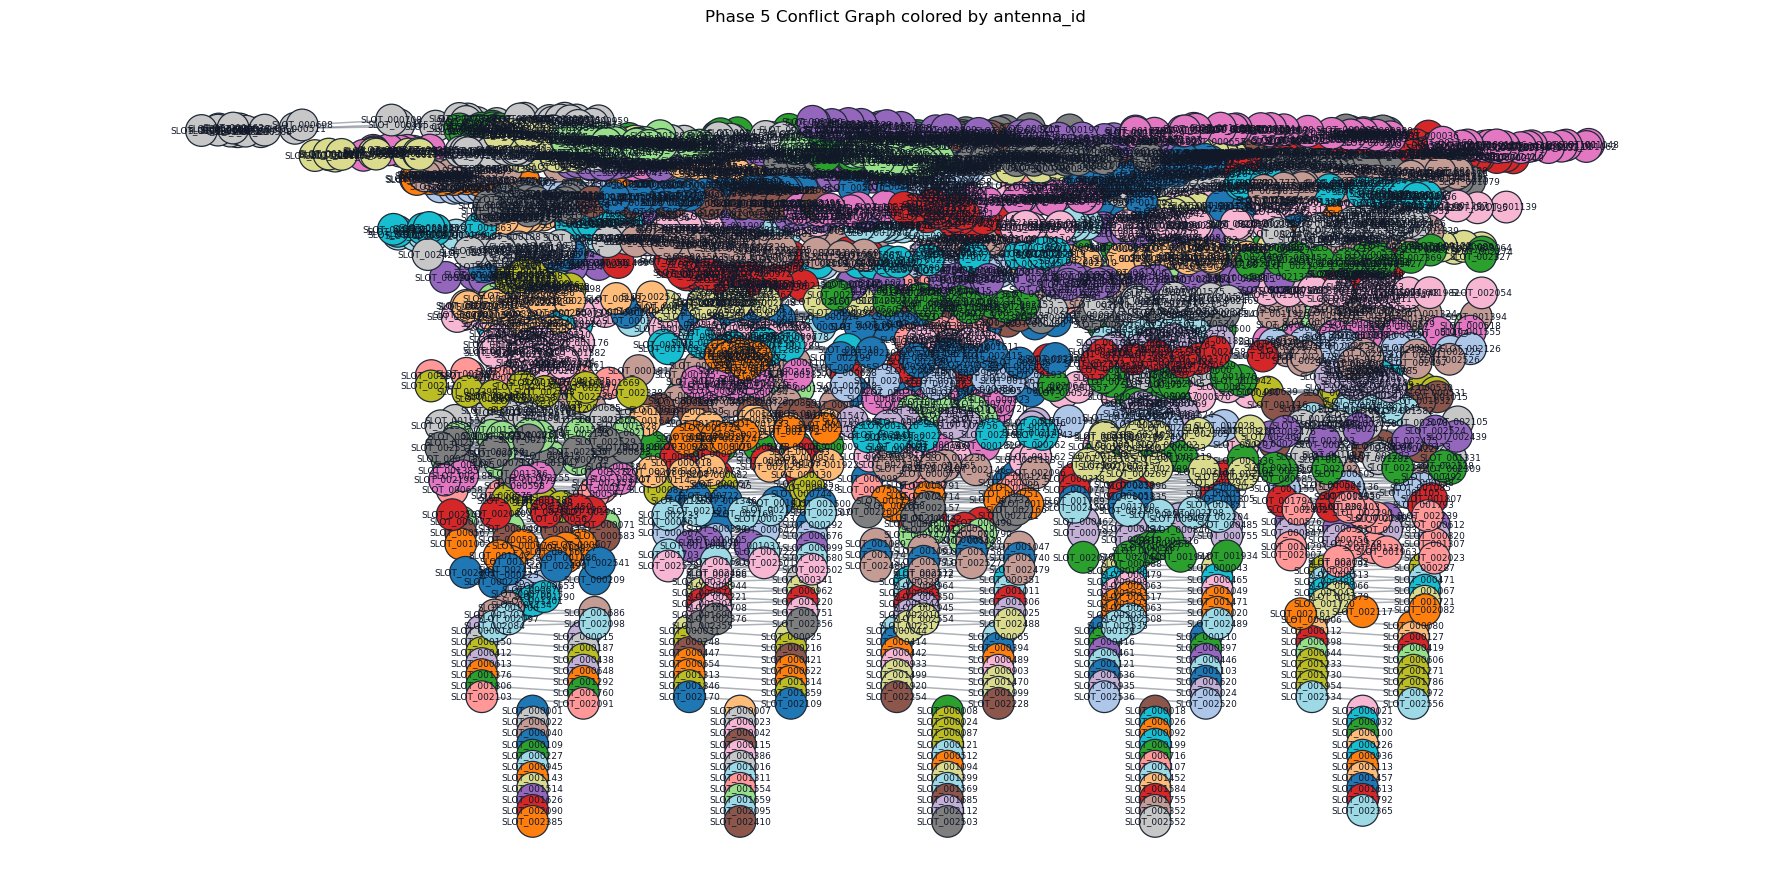

In [59]:
def conflict_graph_component_layout(graph: nx.Graph) -> Dict[str, tuple[float, float]]:
    """Create a spread-out deterministic layout for connected components."""
    positions = {}
    components = sorted(
        nx.connected_components(graph),
        key=lambda component: (-len(component), sorted(component)),
    )

    if not components:
        return positions

    columns = 5
    cell_width = 5.2
    cell_height = 4.2

    for component_index, component_nodes in enumerate(components):
        subgraph = graph.subgraph(component_nodes)
        row = component_index // columns
        column = component_index % columns
        x_offset = column * cell_width
        y_offset = -row * cell_height

        if subgraph.number_of_nodes() == 1:
            node_id = next(iter(component_nodes))
            positions[node_id] = (x_offset, y_offset)
            continue

        local_scale = max(1.2, math.sqrt(subgraph.number_of_nodes()) * 0.9)
        local_positions = nx.spring_layout(
            subgraph,
            seed=42,
            k=1.1,
            scale=local_scale,
            iterations=200,
        )

        for node_id, position in local_positions.items():
            positions[node_id] = (position[0] + x_offset, position[1] + y_offset)

    return positions


def build_node_color_map(graph: nx.Graph, attribute: str = "satellite_id") -> tuple[list[str], dict[str, object]]:
    """Build deterministic node colors from a real graph node attribute.

    Parameters
    ----------
    graph:
        Conflict graph whose nodes contain candidate-slot metadata.
    attribute:
        Node attribute used for coloring, such as `satellite_id` or `antenna_id`.

    Returns
    -------
    tuple[list[str], dict[str, object]]
        Node colors in graph-node order, plus a value-to-color mapping for legends.
    """
    attribute_values = sorted({str(graph.nodes[node_id][attribute]) for node_id in graph.nodes})
    if not attribute_values:
        return [], {}

    color_map = plt.get_cmap("tab20", max(len(attribute_values), 1))
    value_to_color = {
        value: color_map(index)
        for index, value in enumerate(attribute_values)
    }
    node_colors = [
        value_to_color[str(graph.nodes[node_id][attribute])]
        for node_id in graph.nodes
    ]
    return node_colors, value_to_color


def add_color_legend(value_to_color: dict[str, object], title: str, max_entries: int = 32) -> None:
    """Add a compact legend for a dynamically generated color map."""
    if not value_to_color or len(value_to_color) > max_entries:
        return

    handles = [
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            markerfacecolor=color,
            markeredgecolor="#1f2937",
            markersize=7,
            label=value,
        )
        for value, color in value_to_color.items()
    ]
    plt.legend(
        handles=handles,
        title=title,
        loc="center left",
        bbox_to_anchor=(1.01, 0.5),
        fontsize=7,
        title_fontsize=8,
        frameon=False,
    )


def draw_conflict_graph(
    graph: nx.Graph,
    color_by: str = "antenna_id",
    title: str | None = None,
) -> None:
    """Draw a compact conflict graph colored by a real node attribute."""
    plt.figure(figsize=(18, 9))

    positions = conflict_graph_component_layout(graph)
    node_labels = {node_id: node_id for node_id in graph.nodes}
    node_colors, value_to_color = build_node_color_map(graph, attribute=color_by)

    nx.draw_networkx_edges(
        graph,
        positions,
        width=1.1,
        edge_color="#4b5563",
        alpha=0.45,
    )
    nx.draw_networkx_nodes(
        graph,
        positions,
        node_size=520,
        node_color=node_colors,
        edgecolors="#1f2937",
        linewidths=0.9,
    )
    nx.draw_networkx_labels(
        graph,
        positions,
        labels=node_labels,
        font_size=6.5,
        font_color="#111827",
    )

    add_color_legend(value_to_color, title=color_by)
    plt.title(title or f"Phase 5 Conflict Graph colored by {color_by}")
    plt.axis("off")
    plt.margins(0.08)
    plt.tight_layout()
    plt.show()


draw_conflict_graph(phase_5_graph, color_by="antenna_id")


## Phase 5 Validation Checkpoint

This cell verifies that the conflict graph contains the expected nodes, edges, edge reasons, and diagnostics.


In [60]:
phase_5_diagnostics = graph_diagnostics(phase_5_graph)

assert phase_5_diagnostics["node_count"] == len(phase_5_slots)
assert phase_5_diagnostics["edge_count"] == phase_5_graph.number_of_edges()
assert phase_5_diagnostics["component_count"] == len(phase_5_diagnostics["connected_components"])
assert phase_5_diagnostics["density"] >= 0.0
assert phase_5_diagnostics["average_degree"] >= 0.0

for first_node, second_node, edge_data in phase_5_graph.edges(data=True):
    assert edge_data["reason"] in {
        "same communication request",
        "same-antenna overlap",
        "same-antenna reconfiguration time",
    }

print("Phase 5 validation passed: conflict graph builds correctly from the shared dataset.")

source_interval_conflict_count = sum(
    1
    for _, _, edge_data in phase_5_graph.edges(data=True)
    if edge_data["reason"] == "same communication request"
)
print({"same_request_conflict_edges": source_interval_conflict_count})


Phase 5 validation passed: conflict graph builds correctly from the shared dataset.
{'same_request_conflict_edges': 551}


## Phase 6: Natural Connected-Component Decomposition

Phase 6 splits the complete conflict graph into natural independent components.

This step is exact and does not cut any conflicts. If two nodes are in different connected components, there is no path of conflict edges between them, so the scheduling choices in one component cannot affect the choices in the other. Later phases can therefore solve each component separately and add the results together.


In [61]:
def edge_reason_counts(graph: nx.Graph) -> Dict[str, int]:
    """Count conflict reasons inside one graph or component."""
    counts: Dict[str, int] = {}
    for _, _, edge_data in graph.edges(data=True):
        reason = edge_data.get("reason", "unknown")
        counts[reason] = counts.get(reason, 0) + 1
    return dict(sorted(counts.items()))


def component_subgraph_descriptor(component_id: str, graph: nx.Graph) -> Dict[str, object]:
    """Describe one independent conflict-graph component."""
    node_ids = sorted(graph.nodes)
    degrees = dict(graph.degree())
    weights = [graph.nodes[node_id]["weight"] for node_id in node_ids]
    values = lambda attribute: {
        graph.nodes[node_id].get(attribute)
        for node_id in node_ids
        if graph.nodes[node_id].get(attribute) is not None
    }
    return {
        "component_id": component_id,
        "node_count": graph.number_of_nodes(),
        "edge_count": graph.number_of_edges(),
        "density": nx.density(graph),
        "average_degree": 0.0 if not node_ids else sum(degrees.values()) / len(node_ids),
        "max_degree": 0 if not degrees else max(degrees.values()),
        "total_weight": sum(weights),
        "max_weight": None if not weights else max(weights),
        "satellite_count": len(values("satellite_id")),
        "antenna_count": len(values("antenna_id")),
        "source_interval_count": len(values("source_interval_id")),
        "edge_reason_counts": edge_reason_counts(graph),
        "node_ids": node_ids,
    }


def decompose_conflict_graph(graph: nx.Graph) -> list[Dict[str, object]]:
    """Create deterministic independent-component records."""
    node_sets = sorted(nx.connected_components(graph), key=lambda c: (-len(c), sorted(c)))
    records = []
    for index, node_ids in enumerate(node_sets, start=1):
        component_id = f"component_{index:03d}"
        subgraph = graph.subgraph(sorted(node_ids)).copy()
        subgraph.graph["component_id"] = component_id
        records.append({
            "component_id": component_id,
            "graph": subgraph,
            "descriptor": component_subgraph_descriptor(component_id, subgraph),
        })
    return records


def build_node_to_component_map(records: list[Dict[str, object]]) -> Dict[str, str]:
    return {
        node_id: record["component_id"]
        for record in records
        for node_id in record["graph"].nodes
    }


phase_6_components = decompose_conflict_graph(phase_5_graph)
phase_6_component_by_id = {c["component_id"]: c for c in phase_6_components}
phase_6_node_to_component = build_node_to_component_map(phase_6_components)

print("Phase 6 component decomposition:")
print({
    "component_count": len(phase_6_components),
    "total_nodes": sum(c["descriptor"]["node_count"] for c in phase_6_components),
    "total_edges": sum(c["descriptor"]["edge_count"] for c in phase_6_components),
    "largest_component_nodes": max((c["descriptor"]["node_count"] for c in phase_6_components), default=0),
})
print("\nLargest component descriptors:")
for component in phase_6_components[:10]:
    descriptor = dict(component["descriptor"])
    descriptor.pop("node_ids", None)
    print(descriptor)


Phase 6 component decomposition:
{'component_count': 314, 'total_nodes': 2556, 'total_edges': 7245, 'largest_component_nodes': 85}

Largest component descriptors:
{'component_id': 'component_001', 'node_count': 85, 'edge_count': 360, 'density': 0.10084033613445378, 'average_degree': 8.470588235294118, 'max_degree': 12, 'total_weight': 5074.014000000001, 'max_weight': 91.271, 'satellite_count': 52, 'antenna_count': 1, 'source_interval_count': 71, 'edge_reason_counts': {'same communication request': 14, 'same-antenna overlap': 188, 'same-antenna reconfiguration time': 158}}
{'component_id': 'component_002', 'node_count': 66, 'edge_count': 301, 'density': 0.14032634032634034, 'average_degree': 9.121212121212121, 'max_degree': 16, 'total_weight': 3834.0060000000003, 'max_weight': 82.86, 'satellite_count': 45, 'antenna_count': 1, 'source_interval_count': 51, 'edge_reason_counts': {'same communication request': 15, 'same-antenna overlap': 144, 'same-antenna reconfiguration time': 142}}
{'com

## Phase 6 Component Visualizations

The first graphic is a component-level overview. Each displayed node represents one complete independent subgraph—not one candidate slot. Labels show component ID, candidate-slot node count (`n`), and conflict-edge count (`e`). There are no inter-component edges by definition.

The second graphic chooses one non-trivial component with a fixed random seed and draws its internal candidate-slot conflict graph. Colors represent antenna IDs, as in Phase 5.


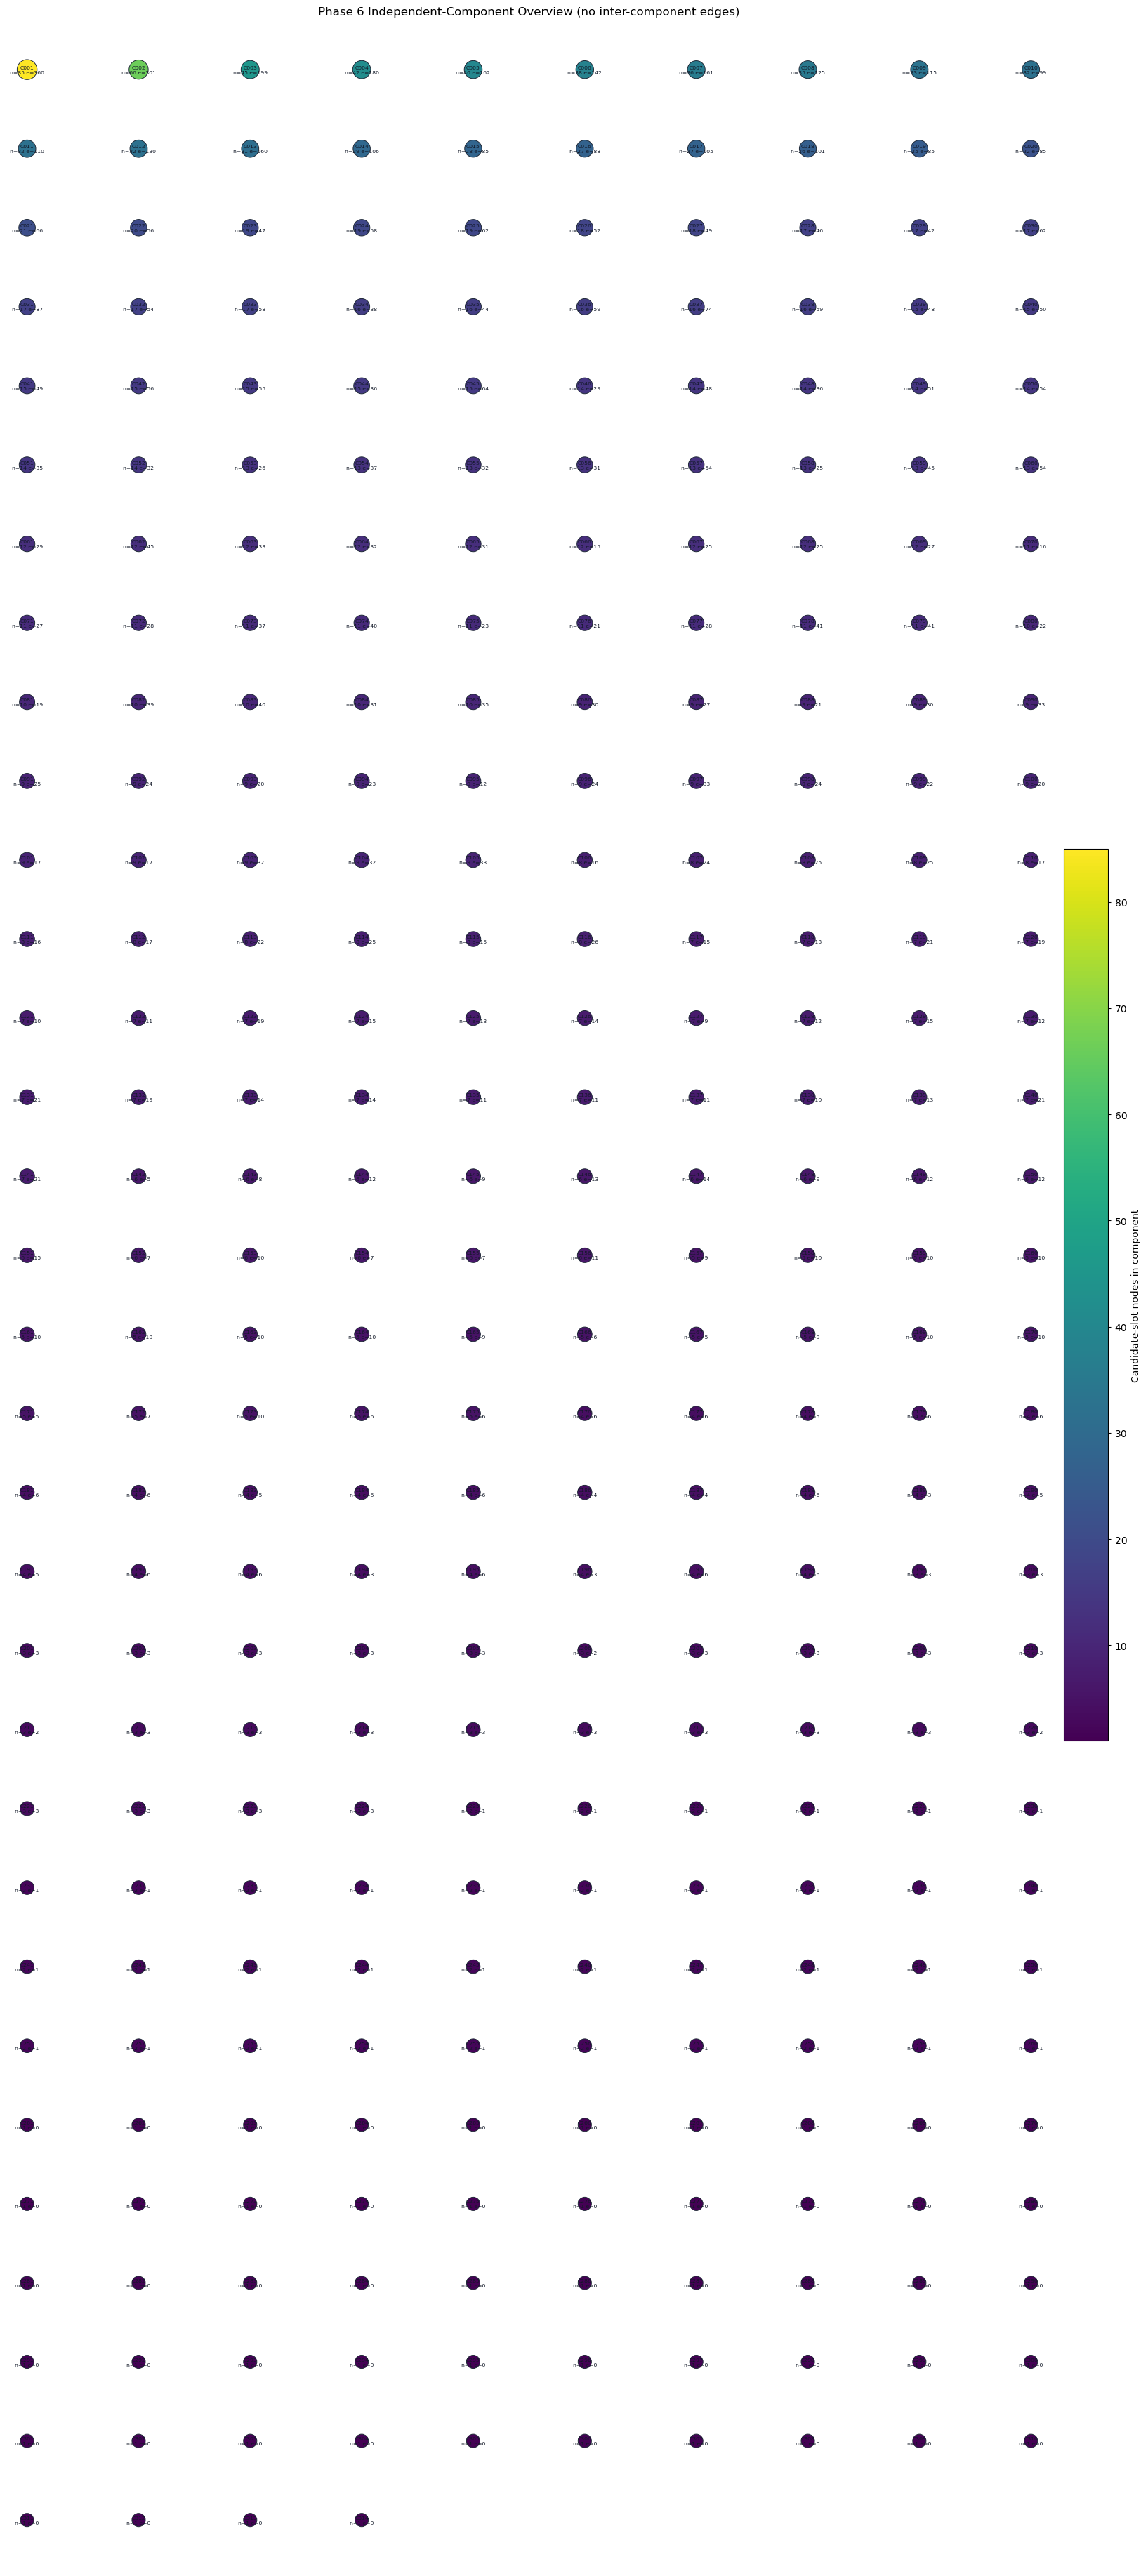

Random component shown below:
{'seed': 42, 'component_id': 'component_058', 'node_count': 13, 'edge_count': 25}


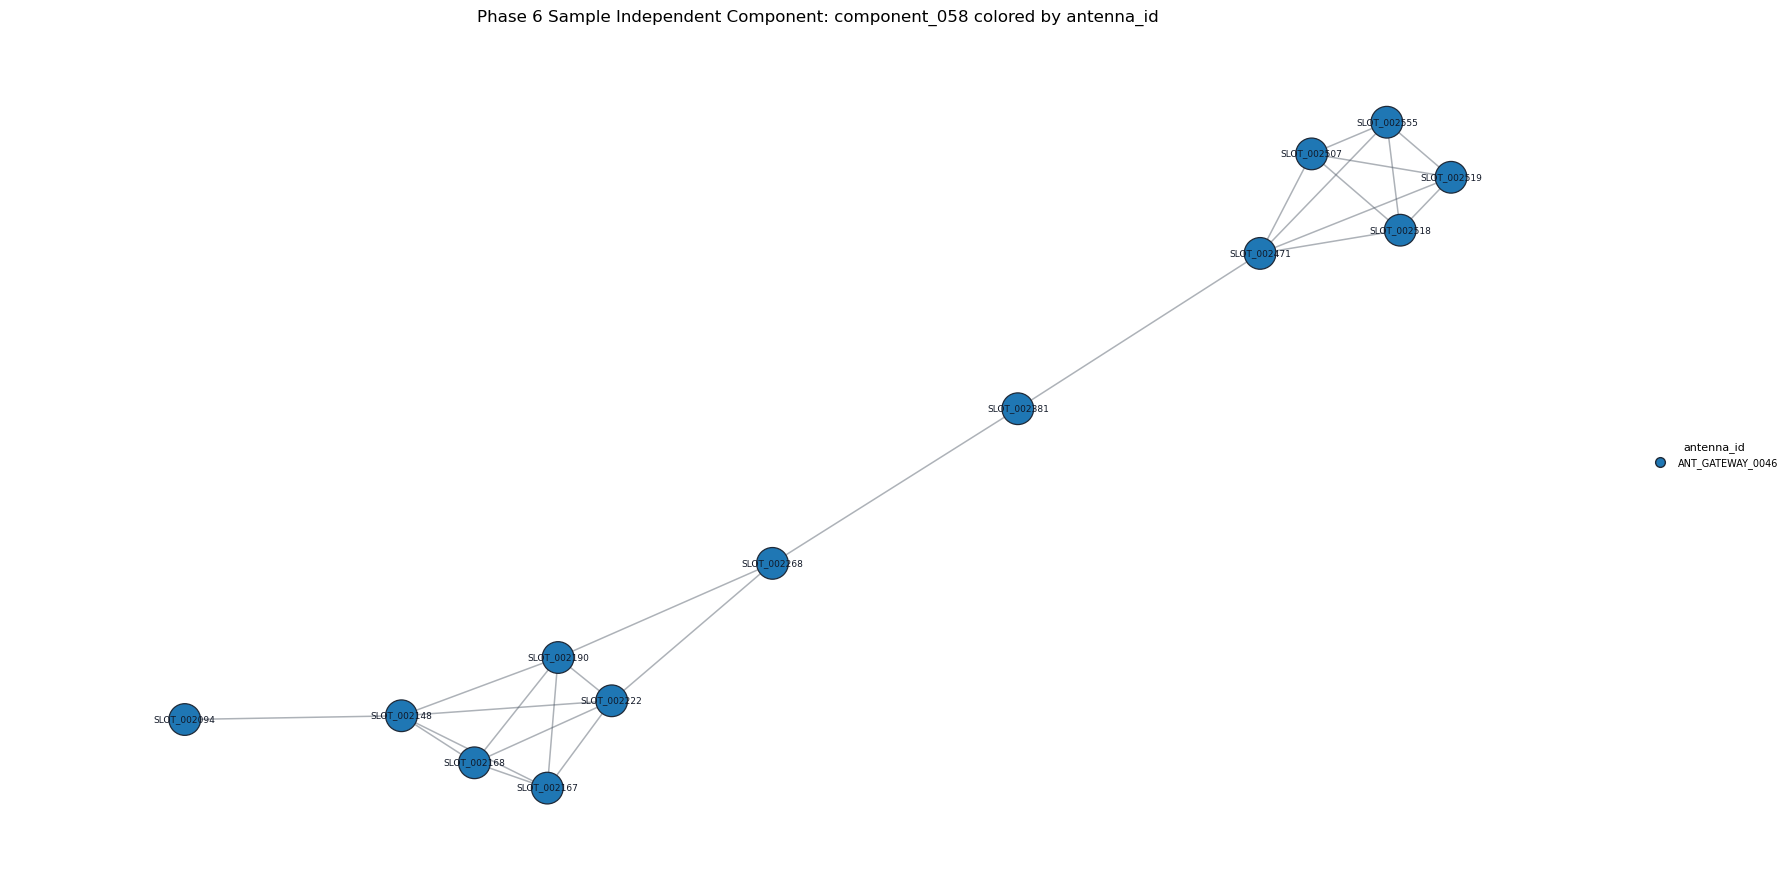

In [62]:
import random


def draw_component_overview(records: list[Dict[str, object]]) -> None:
    """Draw every independent component as one labeled overview node."""
    overview = nx.Graph()
    for record in records:
        descriptor = record["descriptor"]
        overview.add_node(record["component_id"], node_count=descriptor["node_count"], edge_count=descriptor["edge_count"])
    component_ids = list(overview.nodes)
    if not component_ids:
        print("No components to draw.")
        return
    columns = min(10, max(1, math.ceil(math.sqrt(len(component_ids)))))
    rows = math.ceil(len(component_ids) / columns)
    positions = {cid: (i % columns, -(i // columns)) for i, cid in enumerate(component_ids)}
    node_counts = [overview.nodes[cid]["node_count"] for cid in component_ids]
    labels = {
        cid: f"{cid.replace('component_', 'C')}\nn={overview.nodes[cid]['node_count']} e={overview.nodes[cid]['edge_count']}"
        for cid in component_ids
    }
    plt.figure(figsize=(max(16, columns * 1.8), max(8, rows * 1.15)))
    nodes = nx.draw_networkx_nodes(
        overview, positions,
        node_size=[160 + 28 * math.sqrt(count) for count in node_counts],
        node_color=node_counts, cmap="viridis", edgecolors="#1f2937", linewidths=0.7,
    )
    nx.draw_networkx_labels(overview, positions, labels=labels, font_size=5.5, font_color="#111827")
    colorbar = plt.colorbar(nodes, shrink=0.35, pad=0.01)
    colorbar.set_label("Candidate-slot nodes in component")
    plt.title("Phase 6 Independent-Component Overview (no inter-component edges)")
    plt.axis("off")
    plt.margins(0.02)
    plt.tight_layout()
    plt.show()


def choose_random_nontrivial_component(records: list[Dict[str, object]], seed: int = 42) -> Dict[str, object]:
    candidates = [c for c in records if c["descriptor"]["edge_count"] > 0] or list(records)
    if not candidates:
        raise ValueError("Cannot sample from an empty component collection")
    return random.Random(seed).choice(candidates)


draw_component_overview(phase_6_components)
PHASE_6_RANDOM_COMPONENT_SEED = 42
phase_6_random_component = choose_random_nontrivial_component(phase_6_components, PHASE_6_RANDOM_COMPONENT_SEED)
descriptor = phase_6_random_component["descriptor"]
print("Random component shown below:")
print({"seed": PHASE_6_RANDOM_COMPONENT_SEED, "component_id": phase_6_random_component["component_id"], "node_count": descriptor["node_count"], "edge_count": descriptor["edge_count"]})
draw_conflict_graph(
    phase_6_random_component["graph"],
    color_by="antenna_id",
    title=f"Phase 6 Sample Independent Component: {phase_6_random_component['component_id']} colored by antenna_id",
)


## Phase 6 Validation Checkpoint

This proves that decomposition preserves every Phase 5 node and edge exactly once and leaves no edge crossing between component records.


In [63]:
phase_6_total_nodes = sum(c["descriptor"]["node_count"] for c in phase_6_components)
phase_6_total_edges = sum(c["descriptor"]["edge_count"] for c in phase_6_components)
assert phase_6_total_nodes == phase_5_graph.number_of_nodes()
assert phase_6_total_edges == phase_5_graph.number_of_edges()
assert set(phase_6_node_to_component) == set(phase_5_graph.nodes)
assert len(phase_6_components) == nx.number_connected_components(phase_5_graph)
for first_node, second_node in phase_5_graph.edges:
    assert phase_6_node_to_component[first_node] == phase_6_node_to_component[second_node]
for component in phase_6_components:
    assert nx.is_connected(component["graph"])
    assert set(component["descriptor"]["node_ids"]) == set(component["graph"].nodes)
print("Phase 6 validation passed: the full conflict graph is partitioned into exact independent subgraphs.")


Phase 6 validation passed: the full conflict graph is partitioned into exact independent subgraphs.


## Phase 7: Exact QPU-Size Separator Decomposition

Phase 7 handles natural components that are still too large for the configured QPU limits.

If a component already fits the node and coupler limits, it becomes a terminal subproblem directly. If it is too large, the notebook searches for a small separator, enumerates every feasible separator state, and recursively solves the independent residual pieces. This keeps the decomposition exact when it succeeds.

If the exact separator search cannot finish within the configured limits, the component is marked as incomplete. It is not silently treated as exact; Phase 8 can then solve that unresolved part heuristically and report the result as a feasible lower bound with a conservative upper bound.


In [64]:
MAX_QPU_TERMINAL_NODES = 30
MAX_QPU_TERMINAL_COUPLERS = 200
MAX_SEPARATOR_SIZE = 3
MAX_SEPARATOR_CANDIDATE_POOL = 14
MAX_SEPARATOR_STATES = 10_000
MAX_RECURSION_DEPTH = 12
MAX_DECOMPOSITION_NODES = 10_000


def graph_fits_terminal_limits(graph: nx.Graph) -> bool:
    """Return whether a conditioned graph fits the configured logical limits."""
    return (
        graph.number_of_nodes() <= MAX_QPU_TERMINAL_NODES
        and graph.number_of_edges() <= MAX_QPU_TERMINAL_COUPLERS
    )


def exact_preprocess_mwis_graph(graph: nx.Graph) -> Dict[str, object]:
    """Apply only elementary MWIS reductions with immediate proofs."""
    reduced = graph.copy()
    forced_selected = set()
    forced_excluded = set()

    changed = True
    while changed:
        changed = False
        non_positive = {
            node_id for node_id in reduced.nodes
            if reduced.nodes[node_id].get("weight", 0.0) <= 0.0
        }
        if non_positive:
            forced_excluded.update(non_positive)
            reduced.remove_nodes_from(non_positive)
            changed = True

        positive_isolates = {
            node_id for node_id in reduced.nodes
            if reduced.degree(node_id) == 0
            and reduced.nodes[node_id].get("weight", 0.0) > 0.0
        }
        if positive_isolates:
            forced_selected.update(positive_isolates)
            reduced.remove_nodes_from(positive_isolates)
            changed = True

    return {
        "graph": reduced,
        "forced_selected_node_ids": forced_selected,
        "forced_excluded_node_ids": forced_excluded,
        "forced_objective": sum(graph.nodes[node_id]["weight"] for node_id in forced_selected),
    }


def separator_residual_components(graph: nx.Graph, separator: tuple[str, ...]) -> list[set[str]]:
    """Return components after removing a proposed separator."""
    residual = graph.copy()
    residual.remove_nodes_from(separator)
    return [set(component) for component in nx.connected_components(residual)]


def feasible_separator_states(graph: nx.Graph, separator: tuple[str, ...]) -> list[frozenset[str]]:
    """Enumerate every independent selected subset of a separator."""
    states = []
    for state_size in range(len(separator) + 1):
        for state_nodes in combinations(separator, state_size):
            state = frozenset(state_nodes)
            if all(not graph.has_edge(a, b) for a, b in combinations(state, 2)):
                states.append(state)
    return states


def score_separator(graph: nx.Graph, separator: tuple[str, ...]) -> tuple | None:
    """Score a verified separator; lower scores are better."""
    pieces = separator_residual_components(graph, separator)
    if len(pieces) <= 1:
        return None
    largest_piece = max(map(len, pieces), default=0)
    state_count = len(feasible_separator_states(graph, separator))
    imbalance = largest_piece - min(map(len, pieces), default=0)
    return (largest_piece, state_count, imbalance, len(separator), -len(pieces), tuple(sorted(separator)))


def find_exact_separator(graph: nx.Graph) -> Dict[str, object] | None:
    """Find a small useful separator, preferring articulation points and balance."""
    candidates = []
    for node_id in nx.articulation_points(graph):
        separator = (node_id,)
        score = score_separator(graph, separator)
        if score is not None:
            candidates.append((score, separator, "articulation point"))
    if candidates:
        score, separator, method = min(candidates)
        return {"separator": separator, "score": score, "method": method}

    node_ids = sorted(graph.nodes)
    if MAX_SEPARATOR_SIZE >= 2:
        for separator in combinations(node_ids, 2):
            score = score_separator(graph, separator)
            if score is not None:
                candidates.append((score, separator, "exhaustive separator pair"))
        if candidates:
            score, separator, method = min(candidates)
            return {"separator": separator, "score": score, "method": method}

    if MAX_SEPARATOR_SIZE >= 3 and len(node_ids) >= 3:
        centrality = nx.betweenness_centrality(graph)
        pool = sorted(node_ids, key=lambda n: (-centrality[n], n))[:MAX_SEPARATOR_CANDIDATE_POOL]
        for size in range(3, MAX_SEPARATOR_SIZE + 1):
            for separator in combinations(pool, size):
                score = score_separator(graph, separator)
                if score is not None:
                    candidates.append((score, separator, f"centrality-pool separator size {size}"))
            if candidates:
                score, separator, method = min(candidates)
                return {"separator": separator, "score": score, "method": method}
    return None


## Recursive Decomposition Builder

The builder records a decomposition DAG. Repeated conditioned node sets are cached, while resource limits produce an explicit `exact_decomposition_incomplete` node rather than a silent heuristic split.


In [65]:
def build_exact_decomposition_node(
    graph: nx.Graph,
    original_component_id: str,
    context: Dict[str, object],
    depth: int = 0,
) -> Dict[str, object]:
    """Recursively build an exact separator-state decomposition node."""
    cache_key = frozenset(graph.nodes)
    if cache_key in context["cache"]:
        context["cache_hits"] += 1
        return context["cache"][cache_key]

    node_number = context["next_node_number"]
    context["next_node_number"] += 1
    decomposition_node_id = f"{original_component_id}_dnode_{node_number:04d}"
    preprocessing = exact_preprocess_mwis_graph(graph)
    reduced = preprocessing["graph"]
    node = {
        "decomposition_node_id": decomposition_node_id,
        "original_component_id": original_component_id,
        "depth": depth,
        "input_node_ids": sorted(graph.nodes),
        "input_node_count": graph.number_of_nodes(),
        "input_edge_count": graph.number_of_edges(),
        "graph": reduced,
        "forced_selected_node_ids": set(preprocessing["forced_selected_node_ids"]),
        "forced_excluded_node_ids": set(preprocessing["forced_excluded_node_ids"]),
        "forced_objective": preprocessing["forced_objective"],
        "branches": [],
        "children": [],
    }
    context["cache"][cache_key] = node
    context["all_nodes"][decomposition_node_id] = node

    if context["next_node_number"] > MAX_DECOMPOSITION_NODES:
        node.update({"node_type": "incomplete", "status": "exact_decomposition_incomplete", "reason": "decomposition node budget exceeded"})
        context["incomplete_reasons"].append(node["reason"])
        return node
    if depth > MAX_RECURSION_DEPTH:
        node.update({"node_type": "incomplete", "status": "exact_decomposition_incomplete", "reason": "recursion depth exceeded"})
        context["incomplete_reasons"].append(node["reason"])
        return node
    if reduced.number_of_nodes() == 0:
        node.update({"node_type": "terminal", "status": "qpu_terminal", "terminal_reason": "resolved by exact preprocessing"})
        return node

    residual_components = [set(c) for c in nx.connected_components(reduced)]
    if len(residual_components) > 1:
        node.update({"node_type": "independent_sum", "status": "exact_decomposition"})
        node["children"] = [
            build_exact_decomposition_node(reduced.subgraph(sorted(ids)).copy(), original_component_id, context, depth + 1)
            for ids in sorted(residual_components, key=lambda c: (-len(c), sorted(c)))
        ]
        return node

    if graph_fits_terminal_limits(reduced):
        node.update({"node_type": "terminal", "status": "qpu_terminal", "terminal_reason": "fits configured logical limits"})
        return node

    separator_result = find_exact_separator(reduced)
    if separator_result is None:
        node.update({"node_type": "incomplete", "status": "exact_decomposition_incomplete", "reason": "no separator found within configured search limits"})
        context["incomplete_reasons"].append(node["reason"])
        return node

    separator = tuple(separator_result["separator"])
    states = feasible_separator_states(reduced, separator)
    if context["separator_state_count"] + len(states) > MAX_SEPARATOR_STATES:
        node.update({"node_type": "incomplete", "status": "exact_decomposition_incomplete", "reason": "separator-state budget exceeded"})
        context["incomplete_reasons"].append(node["reason"])
        return node

    context["separator_state_count"] += len(states)
    node.update({
        "node_type": "separator",
        "status": "exact_decomposition",
        "separator_node_ids": separator,
        "separator_method": separator_result["method"],
        "separator_score": separator_result["score"],
    })

    separator_set = set(separator)
    for state_index, selected_separator in enumerate(states):
        selected_separator = set(selected_separator)
        excluded_separator = separator_set - selected_separator
        forced_neighbors = set()
        for node_id in selected_separator:
            forced_neighbors.update(reduced.neighbors(node_id))
        forced_neighbors.difference_update(separator_set)

        branch_graph = reduced.copy()
        branch_graph.remove_nodes_from(separator_set | forced_neighbors)
        branch_components = [set(c) for c in nx.connected_components(branch_graph)]
        children = [
            build_exact_decomposition_node(branch_graph.subgraph(sorted(ids)).copy(), original_component_id, context, depth + 1)
            for ids in sorted(branch_components, key=lambda c: (-len(c), sorted(c)))
        ]
        node["branches"].append({
            "state_index": state_index,
            "selected_separator_node_ids": selected_separator,
            "excluded_separator_node_ids": excluded_separator,
            "forced_neighbor_exclusions": forced_neighbors,
            "state_objective": sum(reduced.nodes[n]["weight"] for n in selected_separator),
            "children": children,
        })
    return node


def build_exact_component_decomposition(component: Dict[str, object]) -> Dict[str, object]:
    context = {
        "next_node_number": 1,
        "cache": {},
        "all_nodes": {},
        "cache_hits": 0,
        "separator_state_count": 0,
        "incomplete_reasons": [],
    }
    root = build_exact_decomposition_node(component["graph"], component["component_id"], context)
    unique_nodes = list(context["all_nodes"].values())
    terminals = [n for n in unique_nodes if n["node_type"] == "terminal"]
    incomplete = [n for n in unique_nodes if n["node_type"] == "incomplete"]
    return {
        "component_id": component["component_id"],
        "root": root,
        "nodes_by_id": context["all_nodes"],
        "terminal_nodes": terminals,
        "incomplete_nodes": incomplete,
        "status": "exact_decomposition_complete" if not incomplete else "exact_decomposition_incomplete",
        "separator_state_count": context["separator_state_count"],
        "cache_hits": context["cache_hits"],
        "max_depth": max((n["depth"] for n in unique_nodes), default=0),
    }


def unique_terminal_nodes(decompositions: list[Dict[str, object]]) -> list[Dict[str, object]]:
    seen = {}
    for decomposition in decompositions:
        for terminal in decomposition["terminal_nodes"]:
            seen[terminal["decomposition_node_id"]] = terminal
    return sorted(seen.values(), key=lambda n: (n["original_component_id"], n["decomposition_node_id"]))


phase_7_component_decompositions = [
    build_exact_component_decomposition(component)
    for component in phase_6_components
]
phase_7_terminal_nodes = unique_terminal_nodes(phase_7_component_decompositions)
phase_7_incomplete_decompositions = [
    decomposition for decomposition in phase_7_component_decompositions
    if decomposition["status"] != "exact_decomposition_complete"
]

print("Phase 7 exact-decomposition summary:")
print({
    "natural_components": len(phase_7_component_decompositions),
    "complete_decompositions": len(phase_7_component_decompositions) - len(phase_7_incomplete_decompositions),
    "incomplete_decompositions": len(phase_7_incomplete_decompositions),
    "unique_terminal_graphs": len(phase_7_terminal_nodes),
    "largest_terminal_nodes": max((n["graph"].number_of_nodes() for n in phase_7_terminal_nodes), default=0),
    "largest_terminal_couplers": max((n["graph"].number_of_edges() for n in phase_7_terminal_nodes), default=0),
    "separator_states": sum(d["separator_state_count"] for d in phase_7_component_decompositions),
    "cache_hits": sum(d["cache_hits"] for d in phase_7_component_decompositions),
    "maximum_recursion_depth": max((d["max_depth"] for d in phase_7_component_decompositions), default=0),
})

print("\nOversized natural-component decomposition summaries:")
for component, decomposition in zip(phase_6_components, phase_7_component_decompositions):
    if component["graph"].number_of_nodes() <= MAX_QPU_TERMINAL_NODES:
        continue
    print({
        "component_id": component["component_id"],
        "original_nodes": component["graph"].number_of_nodes(),
        "original_edges": component["graph"].number_of_edges(),
        "status": decomposition["status"],
        "terminal_graphs": len(decomposition["terminal_nodes"]),
        "separator_states": decomposition["separator_state_count"],
        "max_depth": decomposition["max_depth"],
    })


Phase 7 exact-decomposition summary:
{'natural_components': 314, 'complete_decompositions': 314, 'incomplete_decompositions': 0, 'unique_terminal_graphs': 365, 'largest_terminal_nodes': 29, 'largest_terminal_couplers': 145, 'separator_states': 41, 'cache_hits': 10, 'maximum_recursion_depth': 2}

Oversized natural-component decomposition summaries:
{'component_id': 'component_001', 'original_nodes': 85, 'original_edges': 360, 'status': 'exact_decomposition_complete', 'terminal_graphs': 12, 'separator_states': 10, 'max_depth': 2}
{'component_id': 'component_002', 'original_nodes': 66, 'original_edges': 301, 'status': 'exact_decomposition_complete', 'terminal_graphs': 9, 'separator_states': 8, 'max_depth': 2}
{'component_id': 'component_003', 'original_nodes': 45, 'original_edges': 199, 'status': 'exact_decomposition_complete', 'terminal_graphs': 4, 'separator_states': 2, 'max_depth': 1}
{'component_id': 'component_004', 'original_nodes': 42, 'original_edges': 180, 'status': 'exact_decomp

## Exact and Hybrid Decomposition Aggregation

The exact aggregator solves terminal graphs and combines them through the decomposition tree. It returns an exact global optimum only when every decomposition branch is complete.

The hybrid aggregator uses the same exact result whenever possible. If it reaches an incomplete decomposition node, it solves that unresolved subgraph with a deterministic heuristic. The resulting schedule is feasible, but the objective is then a lower bound rather than a certified optimum. A conservative upper bound is also computed so the final gap can be reported.


In [ ]:
def evaluate_exact_decomposition_node(
    node: Dict[str, object],
    terminal_solver,
    memo: Dict[str, Dict[str, object]] | None = None,
) -> Dict[str, object]:
    """Evaluate one exact decomposition DAG node bottom-up."""
    if memo is None:
        memo = {}
    node_id = node["decomposition_node_id"]
    if node_id in memo:
        return memo[node_id]
    if node["node_type"] == "incomplete":
        result = {"status": "exact_decomposition_incomplete", "reason": node["reason"]}
        memo[node_id] = result
        return result

    base_selected = set(node["forced_selected_node_ids"])
    base_objective = node["forced_objective"]
    base_offset = node["forced_objective"]

    if node["node_type"] == "terminal":
        terminal_result = terminal_solver(node["graph"])
        result = {
            "status": terminal_result["status"],
            "selected_node_ids": base_selected | set(terminal_result["selected_node_ids"]),
            "objective_value": base_objective + terminal_result["objective_value"],
            "terminal_objective_sum": terminal_result["objective_value"],
            "offset_objective": base_offset,
            "heuristic_objective_sum": 0.0,
            "used_terminal_node_ids": {node_id} if node["graph"].number_of_nodes() else set(),
            "heuristic_fallback_node_ids": set(),
            "winning_separator_states": {},
        }
        memo[node_id] = result
        return result

    if node["node_type"] == "independent_sum":
        child_results = [evaluate_exact_decomposition_node(child, terminal_solver, memo) for child in node["children"]]
        if any(r["status"] == "exact_decomposition_incomplete" for r in child_results):
            result = {"status": "exact_decomposition_incomplete", "reason": "incomplete child decomposition"}
        else:
            result = {
                "status": "optimal" if all(r["status"] == "optimal" for r in child_results) else "heuristic_feasible",
                "selected_node_ids": base_selected | set().union(*(r["selected_node_ids"] for r in child_results)),
                "objective_value": base_objective + sum(r["objective_value"] for r in child_results),
                "terminal_objective_sum": sum(r["terminal_objective_sum"] for r in child_results),
                "offset_objective": base_offset + sum(r["offset_objective"] for r in child_results),
                "heuristic_objective_sum": sum(r.get("heuristic_objective_sum", 0.0) for r in child_results),
                "used_terminal_node_ids": set().union(*(r["used_terminal_node_ids"] for r in child_results)),
                "heuristic_fallback_node_ids": set().union(*(r.get("heuristic_fallback_node_ids", set()) for r in child_results)),
                "winning_separator_states": {k: v for r in child_results for k, v in r["winning_separator_states"].items()},
            }
        memo[node_id] = result
        return result

    branch_results = []
    for branch in node["branches"]:
        child_results = [evaluate_exact_decomposition_node(child, terminal_solver, memo) for child in branch["children"]]
        if any(r["status"] == "exact_decomposition_incomplete" for r in child_results):
            continue
        selected = base_selected | set(branch["selected_separator_node_ids"])
        for child_result in child_results:
            selected.update(child_result["selected_node_ids"])
        branch_results.append({
            "status": "optimal" if all(r["status"] == "optimal" for r in child_results) else "heuristic_feasible",
            "selected_node_ids": selected,
            "objective_value": base_objective + branch["state_objective"] + sum(r["objective_value"] for r in child_results),
            "terminal_objective_sum": sum(r["terminal_objective_sum"] for r in child_results),
            "offset_objective": base_offset + branch["state_objective"] + sum(r["offset_objective"] for r in child_results),
            "heuristic_objective_sum": sum(r.get("heuristic_objective_sum", 0.0) for r in child_results),
            "used_terminal_node_ids": set().union(*(r["used_terminal_node_ids"] for r in child_results)) if child_results else set(),
            "heuristic_fallback_node_ids": set().union(*(r.get("heuristic_fallback_node_ids", set()) for r in child_results)) if child_results else set(),
            "winning_separator_states": {
                **{k: v for r in child_results for k, v in r["winning_separator_states"].items()},
                node_id: branch["state_index"],
            },
        })
    if not branch_results:
        result = {"status": "exact_decomposition_incomplete", "reason": "no complete separator branch"}
    else:
        result = max(branch_results, key=lambda r: (r["objective_value"], sorted(r["selected_node_ids"])))
    memo[node_id] = result
    return result


def evaluate_exact_decomposition_forest(
    decompositions: list[Dict[str, object]],
    terminal_solver,
    full_graph: nx.Graph,
) -> Dict[str, object]:
    """Evaluate the decomposition forest only when every component is exact."""
    memo = {}
    root_results = [evaluate_exact_decomposition_node(d["root"], terminal_solver, memo) for d in decompositions]
    if any(r["status"] == "exact_decomposition_incomplete" for r in root_results):
        return {"status": "exact_decomposition_incomplete", "component_results": root_results}
    selected = set().union(*(r["selected_node_ids"] for r in root_results))
    return {
        "status": "optimal" if all(r["status"] == "optimal" for r in root_results) else "heuristic_feasible",
        "selected_node_ids": selected,
        "objective_value": sum(r["objective_value"] for r in root_results),
        "full_graph_objective_check": sum(full_graph.nodes[n]["weight"] for n in selected),
        "terminal_objective_sum": sum(r["terminal_objective_sum"] for r in root_results),
        "offset_objective": sum(r["offset_objective"] for r in root_results),
        "heuristic_objective_sum": sum(r.get("heuristic_objective_sum", 0.0) for r in root_results),
        "used_terminal_node_ids": set().union(*(r["used_terminal_node_ids"] for r in root_results)),
        "heuristic_fallback_node_ids": set().union(*(r.get("heuristic_fallback_node_ids", set()) for r in root_results)),
        "winning_separator_states": {k: v for r in root_results for k, v in r["winning_separator_states"].items()},
        "component_results": root_results,
    }


def conservative_mwis_upper_bound(graph: nx.Graph) -> float:
    """Safe but loose MWIS upper bound: at most all positive node weights can be selected."""
    return sum(max(0.0, data.get("weight", 0.0)) for _, data in graph.nodes(data=True))


def evaluate_hybrid_decomposition_node(
    node: Dict[str, object],
    terminal_solver,
    fallback_solver,
    memo: Dict[str, Dict[str, object]] | None = None,
) -> Dict[str, object]:
    """Evaluate one decomposition node, using a heuristic only for incomplete nodes."""
    if memo is None:
        memo = {}
    node_id = node["decomposition_node_id"]
    if node_id in memo:
        return memo[node_id]

    base_selected = set(node.get("forced_selected_node_ids", set()))
    base_objective = node.get("forced_objective", 0.0)

    if node["node_type"] == "incomplete":
        fallback_result = fallback_solver(node["graph"])
        selected = base_selected | set(fallback_result["selected_node_ids"])
        heuristic_objective = fallback_result["objective_value"]
        upper_bound = base_objective + conservative_mwis_upper_bound(node["graph"])
        result = {
            "status": "heuristic_feasible",
            "selected_node_ids": selected,
            "objective_value": base_objective + heuristic_objective,
            "upper_bound": upper_bound,
            "terminal_objective_sum": 0.0,
            "offset_objective": base_objective,
            "heuristic_objective_sum": heuristic_objective,
            "used_terminal_node_ids": set(),
            "heuristic_fallback_node_ids": {node_id},
            "winning_separator_states": {},
            "fallback_details": [{
                "decomposition_node_id": node_id,
                "original_component_id": node["original_component_id"],
                "reason": node["reason"],
                "node_count": node["graph"].number_of_nodes(),
                "edge_count": node["graph"].number_of_edges(),
                "heuristic_objective": heuristic_objective,
                "conservative_upper_bound": upper_bound,
                "solver": fallback_result["solver"],
            }],
        }
        memo[node_id] = result
        return result

    if node["node_type"] == "terminal":
        terminal_result = terminal_solver(node["graph"])
        objective = base_objective + terminal_result["objective_value"]
        terminal_is_exact = terminal_result["status"] == "optimal"
        upper_bound = objective if terminal_is_exact else base_objective + conservative_mwis_upper_bound(node["graph"])
        result = {
            "status": terminal_result["status"],
            "selected_node_ids": base_selected | set(terminal_result["selected_node_ids"]),
            "objective_value": objective,
            "upper_bound": upper_bound,
            "terminal_objective_sum": terminal_result["objective_value"] if terminal_is_exact else 0.0,
            "offset_objective": base_objective,
            "heuristic_objective_sum": 0.0 if terminal_is_exact else terminal_result["objective_value"],
            "used_terminal_node_ids": {node_id} if node["graph"].number_of_nodes() and terminal_is_exact else set(),
            "heuristic_fallback_node_ids": set(),
            "winning_separator_states": {},
            "fallback_details": [] if terminal_is_exact else [{
                "decomposition_node_id": node_id,
                "original_component_id": node["original_component_id"],
                "reason": "terminal solver returned a heuristic result",
                "node_count": node["graph"].number_of_nodes(),
                "edge_count": node["graph"].number_of_edges(),
                "heuristic_objective": terminal_result["objective_value"],
                "conservative_upper_bound": upper_bound,
                "solver": terminal_result["solver"],
            }],
        }
        memo[node_id] = result
        return result

    if node["node_type"] == "independent_sum":
        child_results = [
            evaluate_hybrid_decomposition_node(child, terminal_solver, fallback_solver, memo)
            for child in node["children"]
        ]
        selected = base_selected | set().union(*(r["selected_node_ids"] for r in child_results))
        result = {
            "status": "optimal" if all(r["status"] == "optimal" for r in child_results) else "heuristic_feasible",
            "selected_node_ids": selected,
            "objective_value": base_objective + sum(r["objective_value"] for r in child_results),
            "upper_bound": base_objective + sum(r["upper_bound"] for r in child_results),
            "terminal_objective_sum": sum(r["terminal_objective_sum"] for r in child_results),
            "offset_objective": base_objective + sum(r["offset_objective"] for r in child_results),
            "heuristic_objective_sum": sum(r["heuristic_objective_sum"] for r in child_results),
            "used_terminal_node_ids": set().union(*(r["used_terminal_node_ids"] for r in child_results)),
            "heuristic_fallback_node_ids": set().union(*(r["heuristic_fallback_node_ids"] for r in child_results)),
            "winning_separator_states": {k: v for r in child_results for k, v in r["winning_separator_states"].items()},
            "fallback_details": [detail for r in child_results for detail in r["fallback_details"]],
        }
        memo[node_id] = result
        return result

    branch_results = []
    branch_upper_bounds = []
    for branch in node["branches"]:
        child_results = [
            evaluate_hybrid_decomposition_node(child, terminal_solver, fallback_solver, memo)
            for child in branch["children"]
        ]
        selected = base_selected | set(branch["selected_separator_node_ids"])
        for child_result in child_results:
            selected.update(child_result["selected_node_ids"])

        branch_upper_bound = base_objective + branch["state_objective"] + sum(r["upper_bound"] for r in child_results)
        branch_upper_bounds.append(branch_upper_bound)
        branch_results.append({
            "status": "optimal" if all(r["status"] == "optimal" for r in child_results) else "heuristic_feasible",
            "selected_node_ids": selected,
            "objective_value": base_objective + branch["state_objective"] + sum(r["objective_value"] for r in child_results),
            "upper_bound": branch_upper_bound,
            "terminal_objective_sum": sum(r["terminal_objective_sum"] for r in child_results),
            "offset_objective": base_objective + branch["state_objective"] + sum(r["offset_objective"] for r in child_results),
            "heuristic_objective_sum": sum(r["heuristic_objective_sum"] for r in child_results),
            "used_terminal_node_ids": set().union(*(r["used_terminal_node_ids"] for r in child_results)) if child_results else set(),
            "heuristic_fallback_node_ids": set().union(*(r["heuristic_fallback_node_ids"] for r in child_results)) if child_results else set(),
            "winning_separator_states": {
                **{k: v for r in child_results for k, v in r["winning_separator_states"].items()},
                node_id: branch["state_index"],
            },
            "fallback_details": [detail for r in child_results for detail in r["fallback_details"]],
        })

    result = max(branch_results, key=lambda r: (r["objective_value"], sorted(r["selected_node_ids"])))
    result["upper_bound"] = max(branch_upper_bounds, default=result["objective_value"])
    if any(r["status"] != "optimal" for r in branch_results) or result["objective_value"] < result["upper_bound"] - 1e-9:
        result["status"] = "heuristic_feasible"
    memo[node_id] = result
    return result


def evaluate_hybrid_decomposition_forest(
    decompositions: list[Dict[str, object]],
    terminal_solver,
    fallback_solver,
    full_graph: nx.Graph,
) -> Dict[str, object]:
    """Return a complete feasible schedule, with bounds if any fallback is used."""
    memo = {}
    root_results = [
        evaluate_hybrid_decomposition_node(d["root"], terminal_solver, fallback_solver, memo)
        for d in decompositions
    ]
    selected = set().union(*(r["selected_node_ids"] for r in root_results))
    objective_value = sum(r["objective_value"] for r in root_results)
    upper_bound = sum(r["upper_bound"] for r in root_results)
    heuristic_component_results = [r for r in root_results if r["status"] != "optimal"]
    return {
        "status": "optimal" if not heuristic_component_results else "heuristic_feasible",
        "selected_node_ids": selected,
        "objective_value": objective_value,
        "upper_bound": upper_bound,
        "absolute_gap_bound": upper_bound - objective_value,
        "relative_gap_bound_percent": 0.0 if upper_bound == 0 else 100.0 * (upper_bound - objective_value) / upper_bound,
        "full_graph_objective_check": sum(full_graph.nodes[n]["weight"] for n in selected),
        "terminal_objective_sum": sum(r["terminal_objective_sum"] for r in root_results),
        "offset_objective": sum(r["offset_objective"] for r in root_results),
        "heuristic_objective_sum": sum(r["heuristic_objective_sum"] for r in root_results),
        "used_terminal_node_ids": set().union(*(r["used_terminal_node_ids"] for r in root_results)),
        "heuristic_fallback_node_ids": set().union(*(r["heuristic_fallback_node_ids"] for r in root_results)),
        "winning_separator_states": {k: v for r in root_results for k, v in r["winning_separator_states"].items()},
        "component_results": root_results,
        "exact_component_count": sum(1 for r in root_results if r["status"] == "optimal"),
        "heuristic_component_count": len(heuristic_component_results),
        "exact_components_objective_sum": sum(r["objective_value"] for r in root_results if r["status"] == "optimal"),
        "heuristic_components_objective_sum": sum(r["objective_value"] for r in heuristic_component_results),
        "heuristic_components_upper_bound": sum(r["upper_bound"] for r in heuristic_component_results),
        "fallback_details": [detail for r in root_results for detail in r["fallback_details"]],
    }


## Phase 7 Decomposition Visualizations

The decomposition-tree graphic shows separator decisions, conditioned branches, cached recursive children, and terminal QPU-sized graphs for the largest natural component. A second graphic summarizes terminal node and coupler counts across the full dataset.


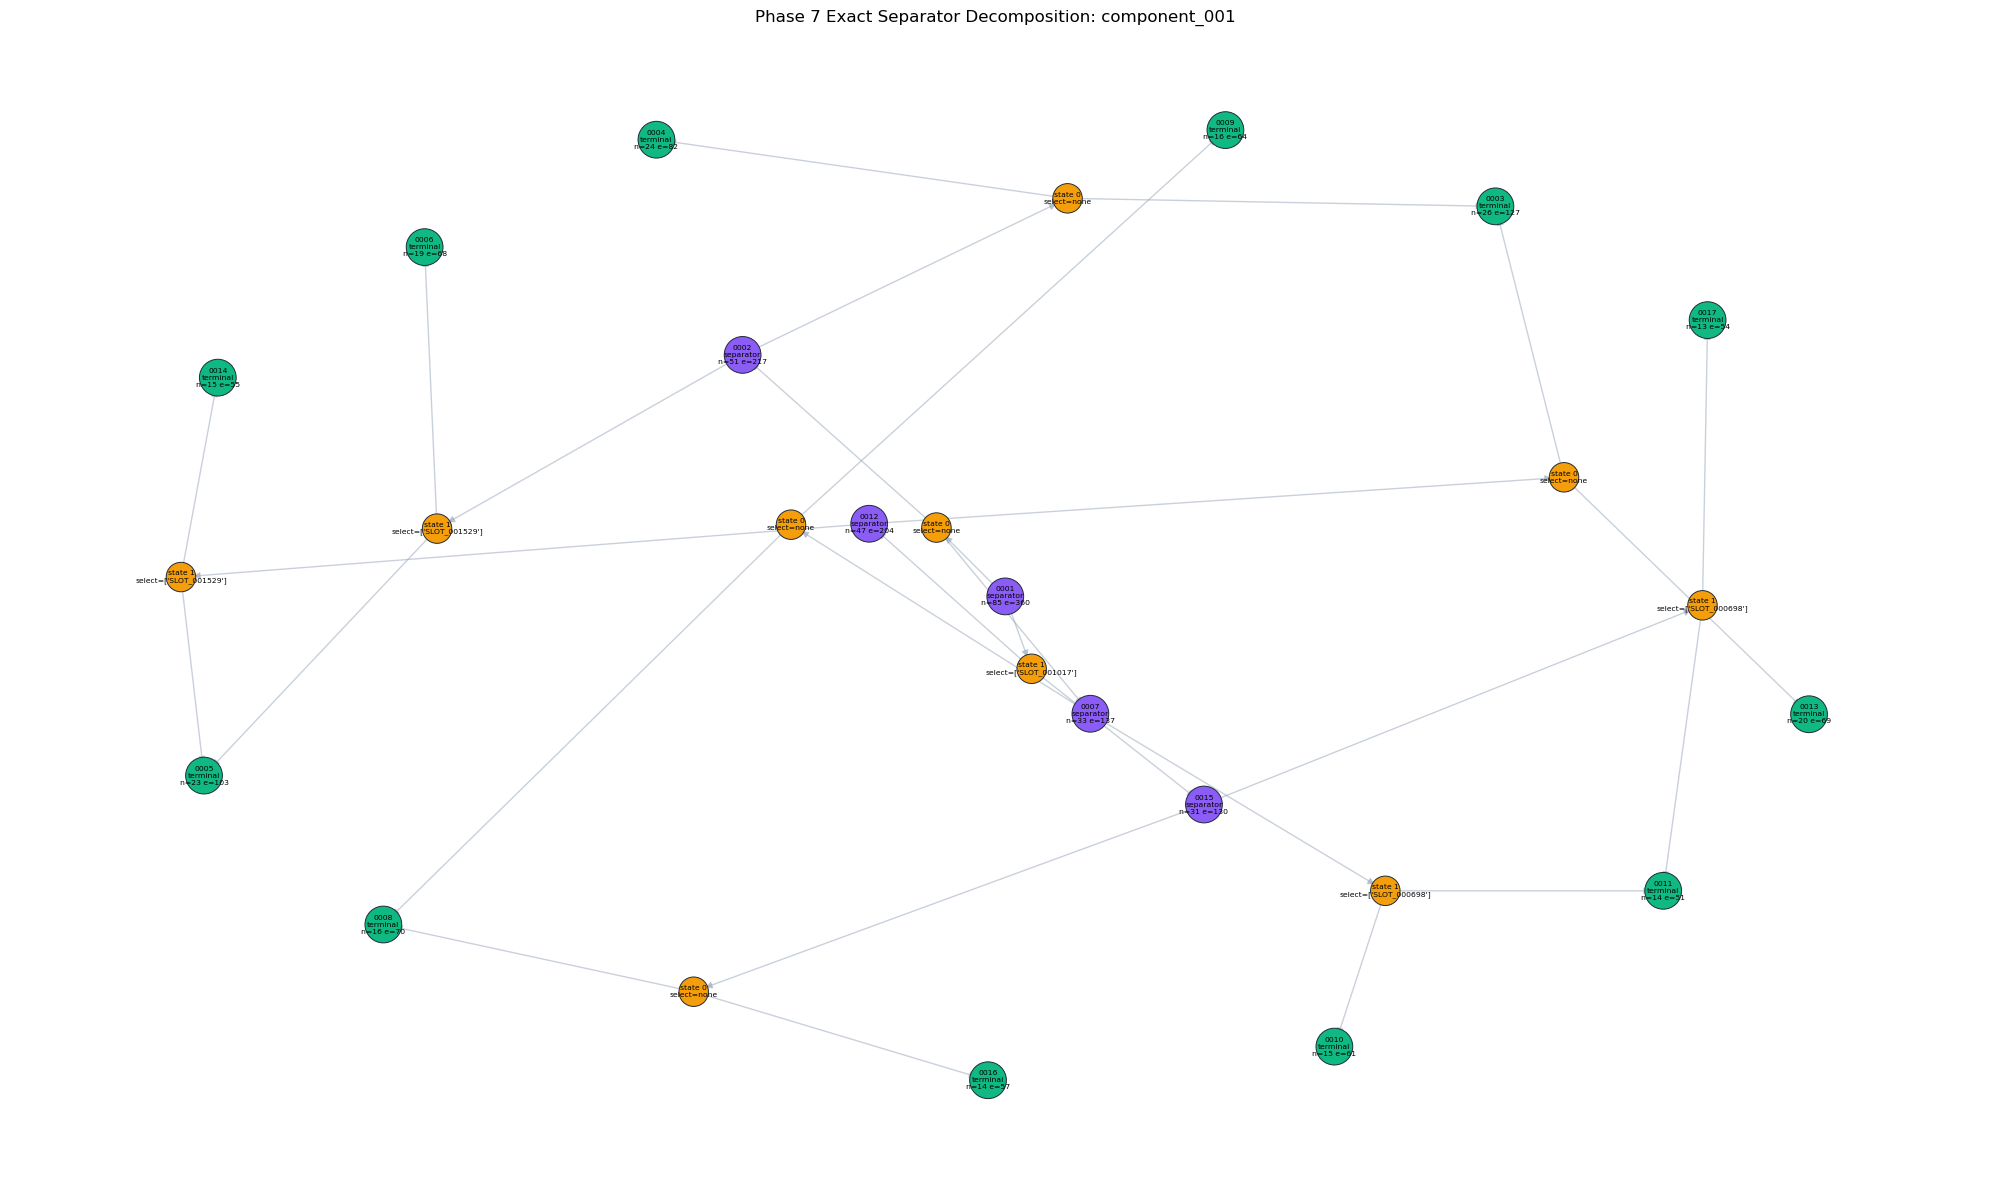

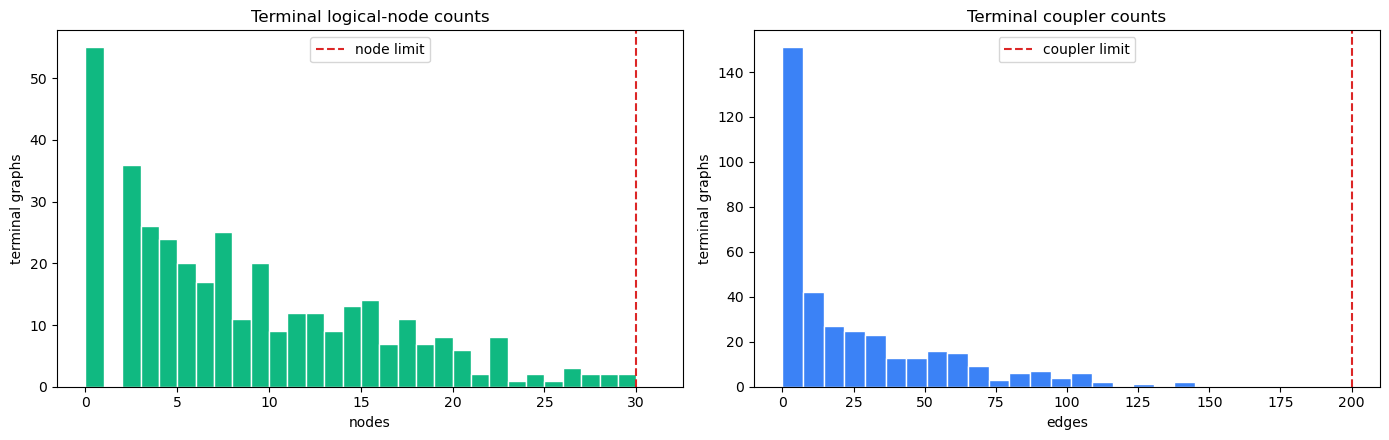

In [67]:
def build_decomposition_visualization_graph(root: Dict[str, object]) -> tuple[nx.DiGraph, Dict[str, str], Dict[str, str]]:
    visual = nx.DiGraph()
    labels = {}
    node_types = {}
    expanded = set()

    def visit(node):
        node_id = node["decomposition_node_id"]
        labels[node_id] = f"{node_id.split('_dnode_')[-1]}\n{node['node_type']}\nn={node['graph'].number_of_nodes()} e={node['graph'].number_of_edges()}"
        node_types[node_id] = node["node_type"]
        visual.add_node(node_id)
        if node_id in expanded:
            return
        expanded.add(node_id)
        if node["node_type"] == "independent_sum":
            for child in node["children"]:
                visual.add_edge(node_id, child["decomposition_node_id"])
                visit(child)
        elif node["node_type"] == "separator":
            for branch in node["branches"]:
                branch_id = f"{node_id}_state_{branch['state_index']}"
                selected = sorted(branch["selected_separator_node_ids"])
                labels[branch_id] = f"state {branch['state_index']}\nselect={selected or 'none'}"
                node_types[branch_id] = "state"
                visual.add_edge(node_id, branch_id)
                for child in branch["children"]:
                    visual.add_edge(branch_id, child["decomposition_node_id"])
                    visit(child)
    visit(root)
    return visual, labels, node_types


def draw_exact_decomposition_tree(decomposition: Dict[str, object]) -> None:
    visual, labels, node_types = build_decomposition_visualization_graph(decomposition["root"])
    colors = {
        "separator": "#8b5cf6", "state": "#f59e0b", "terminal": "#10b981",
        "independent_sum": "#3b82f6", "incomplete": "#ef4444",
    }
    positions = nx.spring_layout(visual, seed=42, k=1.4, iterations=250)
    plt.figure(figsize=(20, 12))
    nx.draw_networkx_edges(visual, positions, edge_color="#94a3b8", alpha=0.5, arrows=True, arrowsize=10)
    nx.draw_networkx_nodes(
        visual, positions,
        node_color=[colors[node_types[n]] for n in visual.nodes],
        node_size=[700 if node_types[n] != "state" else 450 for n in visual.nodes],
        edgecolors="#1f2937", linewidths=0.7,
    )
    nx.draw_networkx_labels(visual, positions, labels=labels, font_size=5.5)
    plt.title(f"Phase 7 Exact Separator Decomposition: {decomposition['component_id']}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


def draw_terminal_size_summary(terminals: list[Dict[str, object]]) -> None:
    node_counts = [n["graph"].number_of_nodes() for n in terminals]
    edge_counts = [n["graph"].number_of_edges() for n in terminals]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].hist(node_counts, bins=range(0, MAX_QPU_TERMINAL_NODES + 2), color="#10b981", edgecolor="white")
    axes[0].axvline(MAX_QPU_TERMINAL_NODES, color="#dc2626", linestyle="--", label="node limit")
    axes[0].set(title="Terminal logical-node counts", xlabel="nodes", ylabel="terminal graphs")
    axes[0].legend()
    axes[1].hist(edge_counts, bins=20, color="#3b82f6", edgecolor="white")
    axes[1].axvline(MAX_QPU_TERMINAL_COUPLERS, color="#dc2626", linestyle="--", label="coupler limit")
    axes[1].set(title="Terminal coupler counts", xlabel="edges", ylabel="terminal graphs")
    axes[1].legend()
    plt.tight_layout()
    plt.show()


largest_decomposition = max(
    phase_7_component_decompositions,
    key=lambda d: d["root"]["input_node_count"],
)
draw_exact_decomposition_tree(largest_decomposition)
draw_terminal_size_summary(phase_7_terminal_nodes)


## Phase 7 Exhaustive Correctness Tests

Small graphs are decomposed under deliberately tiny terminal limits and compared with direct exhaustive MWIS. A dense clique also verifies that an unavailable separator produces an explicit incomplete status rather than an incorrect split.


In [68]:
def solve_small_mwis_exact(graph: nx.Graph) -> Dict[str, object]:
    node_ids = sorted(graph.nodes)
    best_nodes = set()
    best_value = 0.0
    for size in range(len(node_ids) + 1):
        for subset in combinations(node_ids, size):
            selected = set(subset)
            if any(graph.has_edge(a, b) for a, b in combinations(selected, 2)):
                continue
            value = sum(graph.nodes[n]["weight"] for n in selected)
            if value > best_value:
                best_nodes, best_value = selected, value
    return {"selected_node_ids": best_nodes, "objective_value": best_value, "status": "optimal"}


def weighted_test_graph(graph: nx.Graph) -> nx.Graph:
    graph = nx.relabel_nodes(graph, lambda n: f"n{n}")
    for index, node_id in enumerate(sorted(graph.nodes)):
        graph.nodes[node_id]["weight"] = float(1 + (index * 7) % 11)
    return graph


saved_limits = (
    MAX_QPU_TERMINAL_NODES, MAX_QPU_TERMINAL_COUPLERS,
    MAX_SEPARATOR_SIZE, MAX_SEPARATOR_STATES,
)
MAX_QPU_TERMINAL_NODES = 3
MAX_QPU_TERMINAL_COUPLERS = 10
MAX_SEPARATOR_SIZE = 2
MAX_SEPARATOR_STATES = 2_000

phase_7_test_graphs = [
    weighted_test_graph(nx.path_graph(8)),
    weighted_test_graph(nx.cycle_graph(7)),
    weighted_test_graph(nx.balanced_tree(2, 2)),
    weighted_test_graph(nx.barbell_graph(3, 1)),
]
for test_index, test_graph in enumerate(phase_7_test_graphs, start=1):
    component = {"component_id": f"test_{test_index:02d}", "graph": test_graph}
    decomposition = build_exact_component_decomposition(component)
    assert decomposition["status"] == "exact_decomposition_complete"
    decomposed = evaluate_exact_decomposition_forest([decomposition], solve_small_mwis_exact, test_graph)
    direct = solve_small_mwis_exact(test_graph)
    assert decomposed["status"] == "optimal"
    assert math.isclose(decomposed["objective_value"], direct["objective_value"])
    assert all(not test_graph.has_edge(a, b) for a, b in combinations(decomposed["selected_node_ids"], 2))

clique = weighted_test_graph(nx.complete_graph(6))
clique_decomposition = build_exact_component_decomposition({"component_id": "test_clique", "graph": clique})
assert clique_decomposition["status"] == "exact_decomposition_incomplete"

(
    MAX_QPU_TERMINAL_NODES, MAX_QPU_TERMINAL_COUPLERS,
    MAX_SEPARATOR_SIZE, MAX_SEPARATOR_STATES,
) = saved_limits
print("Phase 7 exhaustive tests passed: exact decompositions match direct MWIS and unsupported cuts fail explicitly.")


Phase 7 exhaustive tests passed: exact decompositions match direct MWIS and unsupported cuts fail explicitly.


## Phase 7 Validation Checkpoint

This checkpoint requires every current-dataset terminal graph to fit the configured limits and every natural component decomposition to be complete. It also validates every stored separator state and resource counter.


In [ ]:
assert len(phase_7_component_decompositions) == len(phase_6_components)
assert phase_7_terminal_nodes or phase_7_incomplete_decompositions
assert all(graph_fits_terminal_limits(node["graph"]) for node in phase_7_terminal_nodes)
assert all(d["max_depth"] <= MAX_RECURSION_DEPTH for d in phase_7_component_decompositions)
assert sum(d["separator_state_count"] for d in phase_7_component_decompositions) <= MAX_SEPARATOR_STATES * len(phase_7_component_decompositions)
for decomposition in phase_7_component_decompositions:
    for node in decomposition["nodes_by_id"].values():
        if node["node_type"] != "separator":
            continue
        separator = tuple(node["separator_node_ids"])
        assert len(separator_residual_components(node["graph"], separator)) > 1
        expected_states = feasible_separator_states(node["graph"], separator)
        assert len(node["branches"]) == len(expected_states)
        for branch in node["branches"]:
            selected = branch["selected_separator_node_ids"]
            assert all(not node["graph"].has_edge(a, b) for a, b in combinations(selected, 2))

if phase_7_incomplete_decompositions:
    print("Phase 7 validation passed: exact decomposition is explicit about incomplete components; Phase 8 will use heuristic fallback for them.")
    print({"incomplete_decompositions": len(phase_7_incomplete_decompositions)})
else:
    print("Phase 7 validation passed: current components have a complete exact decomposition into QPU-sized terminal graphs.")


## Phase 8: Classical Reconstruction with Optional Heuristic Fallback

Phase 8 reconstructs a full schedule from the decomposition tree.

First, it tries the fully exact path: every terminal graph is solved exactly and separator states are aggregated exactly. If every component is complete, this gives the global optimum.

Second, it always builds a practical hybrid result. For complete components, the hybrid result is identical to the exact result. For incomplete components, it solves only the unresolved subgraph with a deterministic heuristic, then reports the objective as a feasible lower bound with a conservative upper bound.


## Terminal and Fallback MWIS Solvers

Terminal QPU-sized graphs are solved with exact classical MWIS routines for the benchmark. The fallback solver is deliberately separate: it is deterministic and feasible, but not exact. This separation keeps the notebook honest about which parts of the final schedule are certified optimal and which parts are heuristic.


In [ ]:
MAX_EXACT_MWIS_COMPONENT_NODES = 35
EXACT_ENUMERATION_COMPONENT_LIMIT = 22


def is_independent_node_set(graph: nx.Graph, selected_node_ids: set[str]) -> bool:
    """Return True when no selected node pair is connected by a conflict edge."""
    for first_node, second_node in combinations(selected_node_ids, 2):
        if graph.has_edge(first_node, second_node):
            return False

    return True


def compute_node_set_weight(graph: nx.Graph, selected_node_ids: set[str]) -> float:
    """Compute the total graph weight of selected nodes."""
    return sum(graph.nodes[node_id]["weight"] for node_id in selected_node_ids)


def solve_mwis_by_enumeration(graph: nx.Graph) -> Dict[str, object]:
    """Solve MWIS exactly by enumerating all node subsets.

    This fallback is exponential and intended only for small connected
    components, not for the full realistic graph.
    """
    node_ids = sorted(graph.nodes)
    best_selected_node_ids = set()
    best_objective_value = 0.0

    for subset_size in range(len(node_ids) + 1):
        for node_subset in combinations(node_ids, subset_size):
            selected_node_ids = set(node_subset)

            if not is_independent_node_set(graph, selected_node_ids):
                continue

            objective_value = compute_node_set_weight(graph, selected_node_ids)
            if objective_value > best_objective_value:
                best_selected_node_ids = selected_node_ids
                best_objective_value = objective_value

    return {
        "selected_node_ids": best_selected_node_ids,
        "objective_value": best_objective_value,
        "solver": "exact enumeration",
        "status": "optimal",
    }


def solve_mwis_with_networkx_clique(
    graph: nx.Graph,
    weight_scale: int = 1000,
) -> Dict[str, object]:
    """Solve MWIS exactly as maximum-weight clique on the complement graph.

    NetworkX 2.8 expects integer clique weights, so float slot weights are
    scaled for the solver while the returned objective uses the original
    graph weights. This is used only for bounded connected components.
    """
    complement_graph = nx.complement(graph)

    for node_id, node_data in graph.nodes(data=True):
        complement_graph.nodes[node_id]["scaled_weight"] = int(
            round(node_data["weight"] * weight_scale)
        )

    selected_node_ids, scaled_objective_value = nx.algorithms.clique.max_weight_clique(
        complement_graph,
        weight="scaled_weight",
    )

    selected_node_ids = set(selected_node_ids)
    return {
        "selected_node_ids": selected_node_ids,
        "objective_value": compute_node_set_weight(graph, selected_node_ids),
        "solver": "NetworkX exact max-weight clique on component complement",
        "status": "optimal",
        "weight_scale": weight_scale,
        "reported_scaled_clique_weight": scaled_objective_value,
    }


def solve_mwis_by_weighted_greedy(graph: nx.Graph) -> Dict[str, object]:
    """Build a feasible weighted independent set for a large component.

    This deterministic heuristic is used only when a component cannot be
    decomposed exactly within the configured limits. It returns a feasible
    lower-bound solution, not a proof of optimality.
    """
    remaining_node_ids = set(graph.nodes)
    selected_node_ids = set()

    while remaining_node_ids:
        best_node_id = max(
            remaining_node_ids,
            key=lambda node_id: (
                graph.nodes[node_id]["weight"] / (1 + graph.degree(node_id)),
                graph.nodes[node_id]["weight"],
                -graph.degree(node_id),
                node_id,
            ),
        )
        selected_node_ids.add(best_node_id)
        remaining_node_ids.remove(best_node_id)
        remaining_node_ids.difference_update(graph.neighbors(best_node_id))

    return {
        "selected_node_ids": selected_node_ids,
        "objective_value": compute_node_set_weight(graph, selected_node_ids),
        "solver": "deterministic weighted greedy independent-set heuristic",
        "status": "heuristic_feasible",
    }


def solve_connected_component_mwis(graph: nx.Graph) -> Dict[str, object]:
    """Solve one terminal graph exactly when it is within the exact-solver guard."""
    node_count = graph.number_of_nodes()
    if node_count == 0:
        return {
            "selected_node_ids": set(),
            "objective_value": 0.0,
            "solver": "empty component",
            "status": "optimal",
        }
    if node_count == 1:
        node_id = next(iter(graph.nodes))
        return {
            "selected_node_ids": {node_id},
            "objective_value": compute_node_set_weight(graph, {node_id}),
            "solver": "single-node component shortcut",
            "status": "optimal",
        }
    if node_count > MAX_EXACT_MWIS_COMPONENT_NODES:
        return solve_mwis_by_weighted_greedy(graph)

    if node_count <= EXACT_ENUMERATION_COMPONENT_LIMIT:
        return solve_mwis_by_enumeration(graph)
    return solve_mwis_with_networkx_clique(graph)


def solve_mwis_classically(
    decompositions: list[Dict[str, object]],
    full_graph: nx.Graph,
) -> Dict[str, object]:
    """Solve all complete QPU-sized terminals exactly and reconstruct the full MWIS."""
    return evaluate_exact_decomposition_forest(
        decompositions,
        terminal_solver=solve_connected_component_mwis,
        full_graph=full_graph,
    )


def solve_mwis_with_hybrid_fallback(
    decompositions: list[Dict[str, object]],
    full_graph: nx.Graph,
) -> Dict[str, object]:
    """Return a complete feasible schedule, using heuristic fallback only if needed."""
    return evaluate_hybrid_decomposition_forest(
        decompositions,
        terminal_solver=solve_connected_component_mwis,
        fallback_solver=solve_mwis_by_weighted_greedy,
        full_graph=full_graph,
    )


## Schedule Reconstruction and Feasibility Check

After solving MWIS, the selected graph nodes are mapped back to `CandidateSlot` objects. The reconstructed schedule is then checked directly against the simplified Phase 5 conflict rules.


In [71]:
def reconstruct_selected_schedule(graph: nx.Graph, selected_node_ids: set[str]) -> list[CandidateSlot]:
    """Map selected graph node ids back to candidate slots."""
    return [graph.nodes[node_id]["slot"] for node_id in sorted(selected_node_ids)]


def check_schedule_feasibility(
    selected_slots: list[CandidateSlot],
) -> tuple[bool, list[Dict[str, str]]]:
    """Check selected slots against overlap and antenna-specific reconfiguration conflicts."""
    conflicts = []

    for first_slot, second_slot in combinations(selected_slots, 2):
        if same_source_interval_conflict(first_slot, second_slot):
            conflicts.append(
                {
                    "first_slot_id": first_slot.slot_id,
                    "second_slot_id": second_slot.slot_id,
                    "reason": "same communication request",
                }
            )
        elif same_antenna_overlap_conflict(first_slot, second_slot):
            conflicts.append(
                {
                    "first_slot_id": first_slot.slot_id,
                    "second_slot_id": second_slot.slot_id,
                    "reason": "same-antenna overlap",
                }
            )
        elif same_antenna_reconfiguration_conflict(first_slot, second_slot):
            conflicts.append(
                {
                    "first_slot_id": first_slot.slot_id,
                    "second_slot_id": second_slot.slot_id,
                    "reason": "same-antenna reconfiguration time",
                }
            )

    return len(conflicts) == 0, conflicts


def validate_mwis_solution(
    graph: nx.Graph,
    selected_node_ids: set[str],
) -> Dict[str, object]:
    """Validate the MWIS solution against graph and schedule constraints."""
    selected_slots = reconstruct_selected_schedule(graph, selected_node_ids)
    schedule_is_feasible, schedule_conflicts = check_schedule_feasibility(selected_slots)

    return {
        "is_independent_set": is_independent_node_set(graph, selected_node_ids),
        "schedule_is_feasible": schedule_is_feasible,
        "schedule_conflicts": schedule_conflicts,
        "objective_value": compute_node_set_weight(graph, selected_node_ids),
        "selected_slot_count": len(selected_node_ids),
    }


## Phase 8 Full-Dataset Reconstruction

The exact reconstruction reports whether the decomposition was fully complete. The hybrid reconstruction always returns a feasible schedule: if no fallback is needed, it is the exact optimum; if fallback is used, it is a feasible lower bound with a conservative upper bound.


In [ ]:
phase_8_exact_solution = solve_mwis_classically(phase_7_component_decompositions, phase_5_graph)
phase_8_solution = solve_mwis_with_hybrid_fallback(phase_7_component_decompositions, phase_5_graph)
phase_8_selected_slots = reconstruct_selected_schedule(phase_5_graph, phase_8_solution["selected_node_ids"])
phase_8_validation = validate_mwis_solution(phase_5_graph, phase_8_solution["selected_node_ids"])

print("Classical MWIS reconstruction through the Phase 7 decomposition:")
print({
    "exact_status": phase_8_exact_solution["status"],
    "hybrid_status": phase_8_solution["status"],
    "used_terminal_graphs": len(phase_8_solution["used_terminal_node_ids"]),
    "heuristic_fallback_subgraphs": len(phase_8_solution["heuristic_fallback_node_ids"]),
    "winning_separator_states": len(phase_8_solution["winning_separator_states"]),
    "selected_node_count": len(phase_8_solution["selected_node_ids"]),
    "feasible_objective_value": phase_8_solution["objective_value"],
    "conservative_upper_bound": phase_8_solution["upper_bound"],
    "absolute_gap_bound": phase_8_solution["absolute_gap_bound"],
    "relative_gap_bound_percent": phase_8_solution["relative_gap_bound_percent"],
    "terminal_objective_sum": phase_8_solution["terminal_objective_sum"],
    "separator_preprocessing_and_forced_offset": phase_8_solution["offset_objective"],
    "heuristic_objective_sum": phase_8_solution["heuristic_objective_sum"],
    "full_graph_objective_check": phase_8_solution["full_graph_objective_check"],
})
print({"validation": phase_8_validation})

if phase_8_solution["fallback_details"]:
    print("\nHeuristic fallback details:")
    for detail in phase_8_solution["fallback_details"][:20]:
        print(detail)

print("\nFirst 20 selected nodes:")
print(sorted(phase_8_solution["selected_node_ids"])[:20])
print("\nFirst 20 selected schedule entries:")
for slot in phase_8_selected_slots[:20]:
    print(slot.as_dict())


## Phase 8 MWIS Solution Visualization

The selected MWIS nodes are highlighted on top of the Phase 5 conflict graph. This keeps the full conflict context visible while making the classical solution easy to inspect. Selected nodes should not have conflict edges between each other.


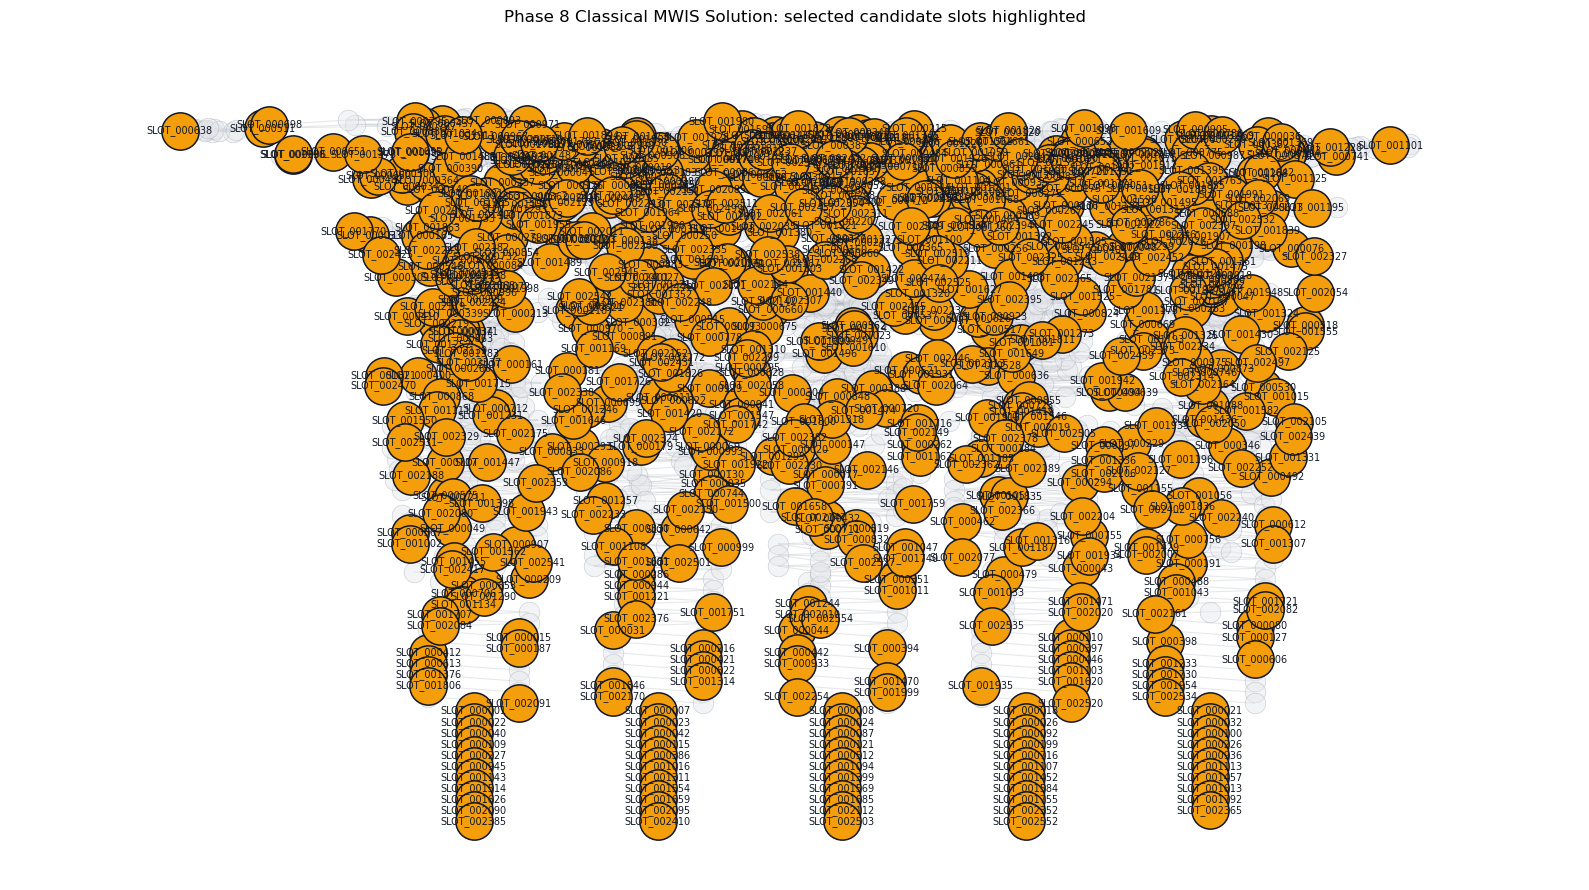

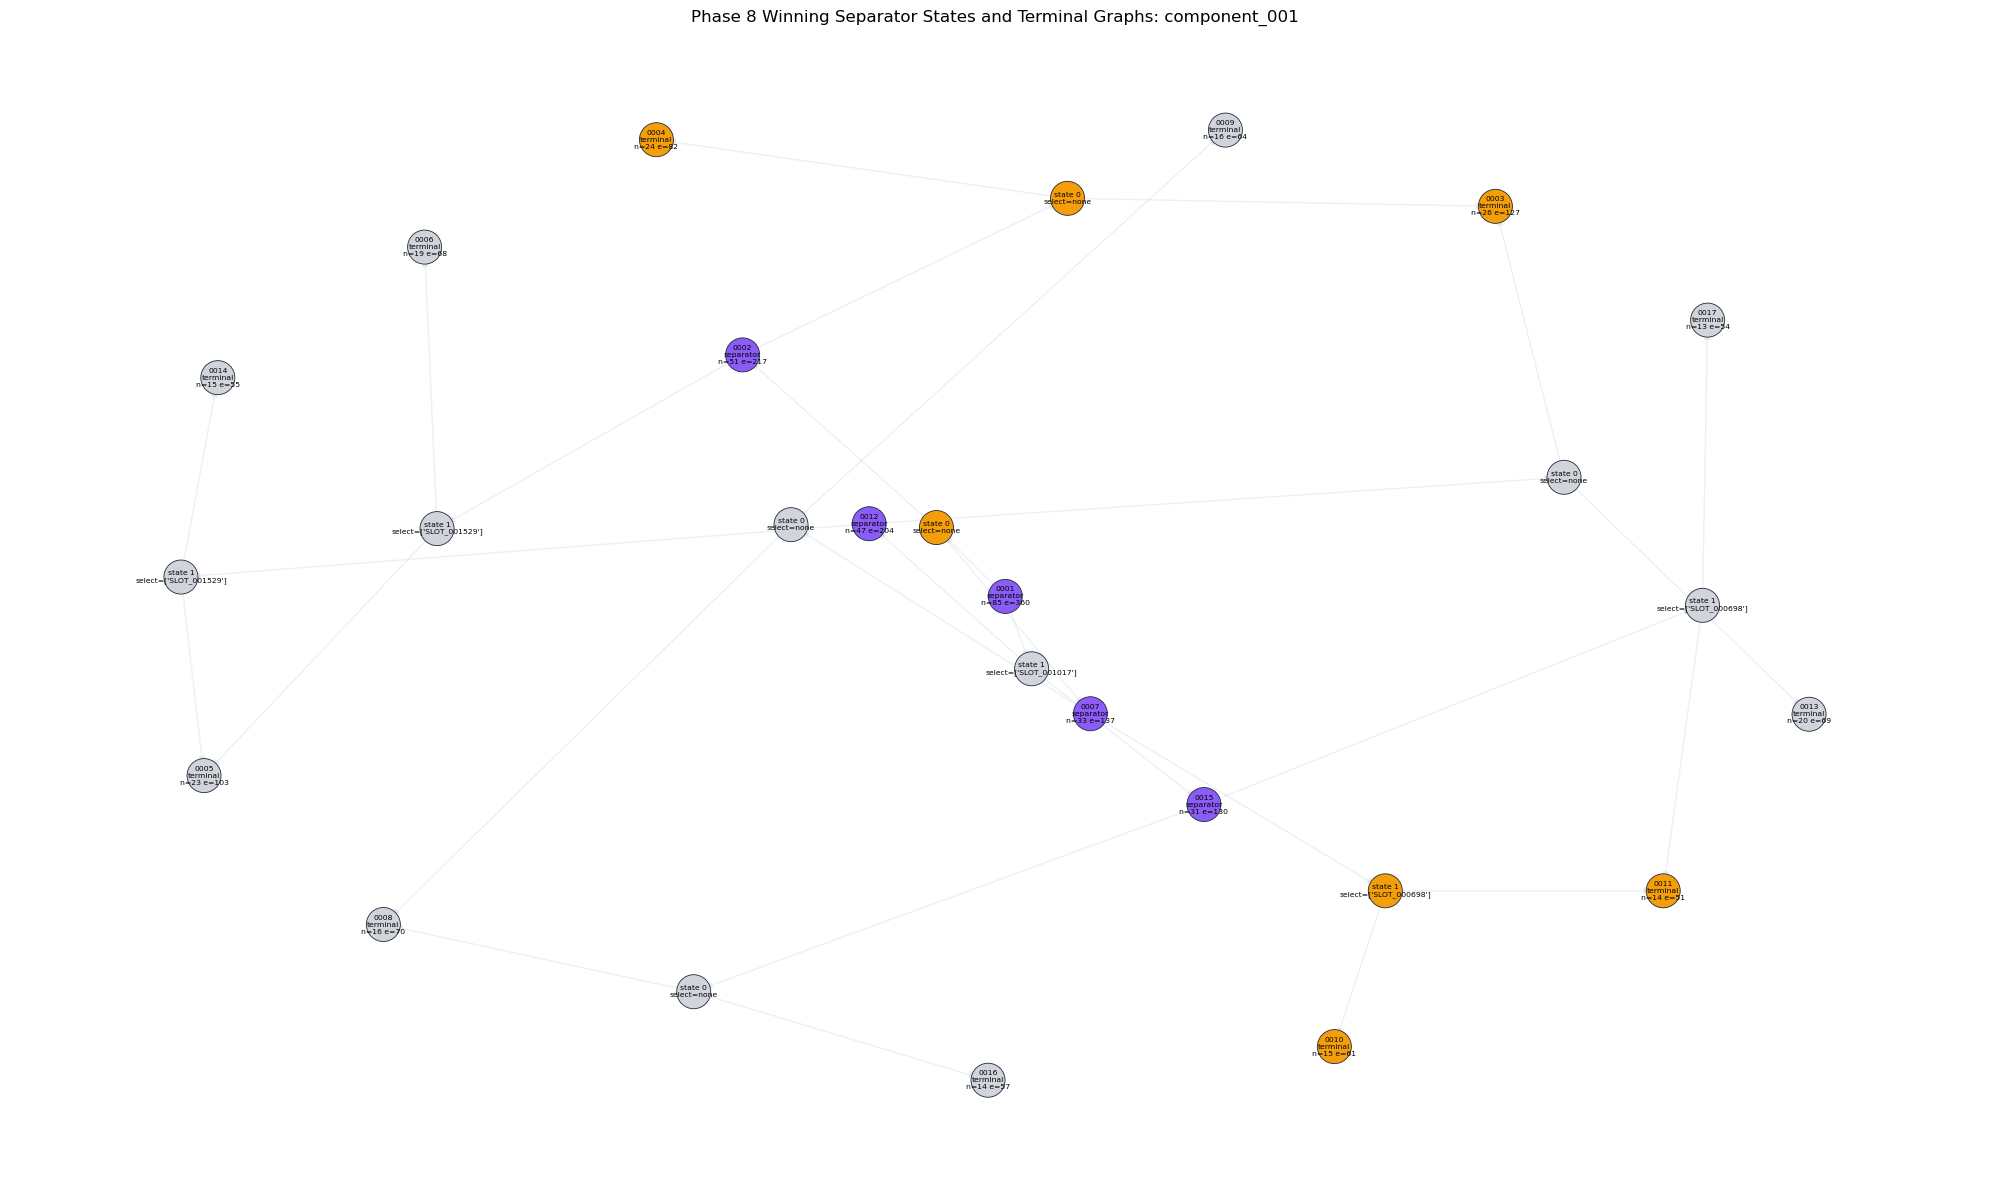

In [73]:
def draw_mwis_solution_graph(
    graph: nx.Graph,
    selected_node_ids: set[str],
) -> None:
    """Draw the conflict graph with the MWIS solution highlighted."""
    positions = conflict_graph_component_layout(graph)

    selected_node_ids = set(selected_node_ids)
    non_selected_node_ids = [node_id for node_id in graph.nodes if node_id not in selected_node_ids]
    selected_node_list = [node_id for node_id in graph.nodes if node_id in selected_node_ids]

    selected_edges = [
        (first_node, second_node)
        for first_node, second_node in graph.edges
        if first_node in selected_node_ids and second_node in selected_node_ids
    ]
    context_edges = [
        (first_node, second_node)
        for first_node, second_node in graph.edges
        if (first_node, second_node) not in selected_edges
    ]

    plt.figure(figsize=(16, 9))

    nx.draw_networkx_edges(
        graph,
        positions,
        edgelist=context_edges,
        width=0.8,
        edge_color="#9ca3af",
        alpha=0.25,
    )

    # This should draw nothing for a valid independent set, but it makes any
    # accidental selected-selected conflict visually obvious.
    nx.draw_networkx_edges(
        graph,
        positions,
        edgelist=selected_edges,
        width=2.4,
        edge_color="#dc2626",
        alpha=0.9,
    )

    nx.draw_networkx_nodes(
        graph,
        positions,
        nodelist=non_selected_node_ids,
        node_size=220,
        node_color="#e5e7eb",
        edgecolors="#9ca3af",
        linewidths=0.5,
        alpha=0.45,
    )
    nx.draw_networkx_nodes(
        graph,
        positions,
        nodelist=selected_node_list,
        node_size=720,
        node_color="#f59e0b",
        edgecolors="#111827",
        linewidths=1.1,
    )

    nx.draw_networkx_labels(
        graph,
        positions,
        labels={node_id: node_id for node_id in selected_node_list},
        font_size=7,
        font_color="#111827",
    )

    plt.title("Phase 8 Classical MWIS Solution: selected candidate slots highlighted")
    plt.axis("off")
    plt.margins(0.08)
    plt.tight_layout()
    plt.show()


draw_mwis_solution_graph(
    phase_5_graph,
    phase_8_solution["selected_node_ids"],
)


def draw_winning_decomposition_path(
    decomposition: Dict[str, object],
    solution: Dict[str, object],
) -> None:
    visual, labels, node_types = build_decomposition_visualization_graph(decomposition["root"])
    winning_states = solution["winning_separator_states"]
    used_terminals = solution["used_terminal_node_ids"]
    winning_branch_nodes = {
        f"{node_id}_state_{state_index}"
        for node_id, state_index in winning_states.items()
        if node_id in decomposition["nodes_by_id"]
    }
    colors = []
    for node_id in visual.nodes:
        if node_id in winning_branch_nodes or node_id in used_terminals:
            colors.append("#f59e0b")
        elif node_types[node_id] == "separator":
            colors.append("#8b5cf6")
        else:
            colors.append("#d1d5db")
    positions = nx.spring_layout(visual, seed=42, k=1.4, iterations=250)
    plt.figure(figsize=(20, 12))
    nx.draw_networkx_edges(visual, positions, edge_color="#cbd5e1", alpha=0.35, arrows=True, arrowsize=10)
    nx.draw_networkx_nodes(visual, positions, node_color=colors, node_size=600, edgecolors="#1f2937", linewidths=0.6)
    nx.draw_networkx_labels(visual, positions, labels=labels, font_size=5.5)
    plt.title(f"Phase 8 Winning Separator States and Terminal Graphs: {decomposition['component_id']}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


draw_winning_decomposition_path(largest_decomposition, phase_8_solution)


## Phase 8 Validation Checkpoint

This cell verifies that the reconstructed schedule is feasible. If no heuristic fallback was used, it also verifies that the result is the exact optimum. If fallback was used, it verifies the lower/upper-bound accounting instead.


In [ ]:
assert phase_8_solution["status"] in {"optimal", "heuristic_feasible"}
assert phase_8_validation["is_independent_set"] is True
assert phase_8_validation["schedule_is_feasible"] is True
assert phase_8_validation["schedule_conflicts"] == []
assert math.isclose(phase_8_solution["objective_value"], phase_8_validation["objective_value"])
assert math.isclose(phase_8_solution["objective_value"], phase_8_solution["full_graph_objective_check"])
assert phase_8_solution["objective_value"] <= phase_8_solution["upper_bound"] + 1e-9
assert phase_8_solution["absolute_gap_bound"] >= -1e-9
assert math.isclose(
    phase_8_solution["objective_value"],
    phase_8_solution["terminal_objective_sum"]
    + phase_8_solution["offset_objective"]
    + phase_8_solution["heuristic_objective_sum"],
)
assert phase_8_validation["selected_slot_count"] == len(phase_8_selected_slots)

if phase_8_exact_solution["status"] == "optimal":
    assert phase_8_solution["status"] == "optimal"
    assert not phase_8_solution["heuristic_fallback_node_ids"]
    assert math.isclose(phase_8_solution["objective_value"], phase_8_exact_solution["objective_value"])
    print("Phase 8 validation passed: exact terminal MWIS results reconstruct the globally optimal full-graph schedule.")
else:
    assert phase_8_solution["status"] == "heuristic_feasible"
    assert phase_8_solution["heuristic_fallback_node_ids"]
    print("Phase 8 validation passed: hybrid fallback produced a feasible schedule with conservative bounds.")


## Phase 9: Terminal QUBO Construction

Phase 9 creates one QUBO for every non-empty terminal graph produced by Phase 7. These are the subproblems that fit the configured QPU limits.

If Phase 8 used heuristic fallback for an incomplete component, that fallback part is not represented as a terminal QUBO. It is reported separately in the final summary table so the exact and heuristic contributions remain visible.


## QUBO Builder

The QUBO is represented as a dictionary keyed by variable pairs:

- `(node_id, node_id)` stores a linear coefficient,
- `(first_node_id, second_node_id)` stores a quadratic conflict coefficient.

Because QUBO solvers minimize energy, node weights become negative diagonal coefficients. Conflict edges become positive quadratic penalties.


In [75]:
Qubo = Dict[tuple[str, str], float]


def default_mwis_penalty(graph: nx.Graph, margin: float = 1.0) -> float:
    """Choose a simple penalty that dominates any single node reward."""
    if graph.number_of_nodes() == 0:
        return margin

    max_weight = max(graph.nodes[node_id]["weight"] for node_id in graph.nodes)
    return max_weight + margin


def canonical_qubo_key(first_node: str, second_node: str) -> tuple[str, str]:
    """Return a stable QUBO key for a linear or quadratic coefficient."""
    if first_node == second_node:
        return (first_node, second_node)

    return tuple(sorted((first_node, second_node)))


def build_mwis_qubo(
    graph: nx.Graph,
    penalty: float | None = None,
) -> Dict[str, object]:
    """Build a minimization QUBO for the MWIS conflict graph."""
    if penalty is None:
        penalty = default_mwis_penalty(graph)

    qubo: Qubo = {}

    for node_id, node_data in graph.nodes(data=True):
        qubo[(node_id, node_id)] = -float(node_data["weight"])

    for first_node, second_node in graph.edges:
        key = canonical_qubo_key(first_node, second_node)
        qubo[key] = qubo.get(key, 0.0) + float(penalty)

    return {
        "qubo": qubo,
        "variables": sorted(graph.nodes),
        "penalty": penalty,
        "offset": 0.0,
    }


## QUBO Diagnostics and Energy Evaluation

These helper functions make the QUBO readable and testable before any quantum or heuristic sampler is introduced.


In [76]:
def selected_nodes_to_binary_sample(
    variables: list[str],
    selected_node_ids: set[str],
) -> Dict[str, int]:
    """Convert a set of selected graph nodes into a binary sample dictionary."""
    return {
        variable: 1 if variable in selected_node_ids else 0
        for variable in variables
    }


def evaluate_qubo_energy(qubo_model: Dict[str, object], sample: Dict[str, int]) -> float:
    """Evaluate QUBO energy for a binary sample."""
    energy = float(qubo_model["offset"])

    for (first_node, second_node), coefficient in qubo_model["qubo"].items():
        energy += coefficient * sample[first_node] * sample[second_node]

    return energy


def qubo_diagnostics(qubo_model: Dict[str, object]) -> Dict[str, object]:
    """Report compact diagnostics for a QUBO model."""
    qubo = qubo_model["qubo"]
    linear_coefficients = [
        coefficient
        for (first_node, second_node), coefficient in qubo.items()
        if first_node == second_node
    ]
    quadratic_coefficients = [
        coefficient
        for (first_node, second_node), coefficient in qubo.items()
        if first_node != second_node
    ]
    all_coefficients = linear_coefficients + quadratic_coefficients

    return {
        "num_variables": len(qubo_model["variables"]),
        "num_linear_terms": len(linear_coefficients),
        "num_quadratic_couplings": len(quadratic_coefficients),
        "penalty": qubo_model["penalty"],
        "linear_coefficient_range": (
            min(linear_coefficients),
            max(linear_coefficients),
        ) if linear_coefficients else None,
        "quadratic_coefficient_range": (
            min(quadratic_coefficients),
            max(quadratic_coefficients),
        ) if quadratic_coefficients else None,
        "coefficient_range": (
            min(all_coefficients),
            max(all_coefficients),
        ) if all_coefficients else None,
    }


def format_qubo_terms(
    qubo_model: Dict[str, object],
    max_terms: int = 20,
) -> list[dict[str, object]]:
    """Return readable QUBO terms for notebook display."""
    formatted_terms = []
    for (first_node, second_node), coefficient in sorted(qubo_model["qubo"].items()):
        formatted_terms.append(
            {
                "term": (first_node, second_node),
                "type": "linear" if first_node == second_node else "quadratic",
                "coefficient": coefficient,
            }
        )

    return formatted_terms[:max_terms]


## Phase 9 Small Test Case

The small graph verifies the QUBO mapping in a case where the correct MWIS is easy to inspect.


In [77]:
phase_9_test_graph = nx.Graph()
phase_9_test_graph.add_node("A", weight=5.0)
phase_9_test_graph.add_node("B", weight=4.0)
phase_9_test_graph.add_node("C", weight=3.0)
phase_9_test_graph.add_edge("A", "B", reason="test conflict")

phase_9_test_penalty = default_mwis_penalty(phase_9_test_graph)
phase_9_test_qubo = build_mwis_qubo(
    phase_9_test_graph,
    penalty=phase_9_test_penalty,
)
phase_9_test_mwis = solve_mwis_by_enumeration(phase_9_test_graph)
phase_9_test_sample = selected_nodes_to_binary_sample(
    phase_9_test_qubo["variables"],
    phase_9_test_mwis["selected_node_ids"],
)
phase_9_test_energy = evaluate_qubo_energy(
    phase_9_test_qubo,
    phase_9_test_sample,
)

print("Small QUBO diagnostics:")
print(qubo_diagnostics(phase_9_test_qubo))
print("Small QUBO terms:")
for term in format_qubo_terms(phase_9_test_qubo):
    print(term)
print("Small graph MWIS solution:")
print(phase_9_test_mwis)
print({"qubo_energy_for_mwis": phase_9_test_energy})


Small QUBO diagnostics:
{'num_variables': 3, 'num_linear_terms': 3, 'num_quadratic_couplings': 1, 'penalty': 6.0, 'linear_coefficient_range': (-5.0, -3.0), 'quadratic_coefficient_range': (6.0, 6.0), 'coefficient_range': (-5.0, 6.0)}
Small QUBO terms:
{'term': ('A', 'A'), 'type': 'linear', 'coefficient': -5.0}
{'term': ('A', 'B'), 'type': 'quadratic', 'coefficient': 6.0}
{'term': ('B', 'B'), 'type': 'linear', 'coefficient': -4.0}
{'term': ('C', 'C'), 'type': 'linear', 'coefficient': -3.0}
Small graph MWIS solution:
{'selected_node_ids': {'C', 'A'}, 'objective_value': 8.0, 'solver': 'exact enumeration', 'status': 'optimal'}
{'qubo_energy_for_mwis': -8.0}


## Phase 9 Shared-Dataset Terminal QUBOs

All terminal branches receive QUBOs because any branch may become the winner under a different terminal solver result. For the classical Phase 8 solution, only QUBOs on the winning reconstruction path contribute to the selected global objective.


In [78]:
phase_9_component_qubos = []
for terminal in phase_7_terminal_nodes:
    graph = terminal["graph"]
    if graph.number_of_nodes() == 0:
        continue
    terminal_id = terminal["decomposition_node_id"]
    descriptor = component_subgraph_descriptor(terminal_id, graph)
    descriptor.update({
        "original_component_id": terminal["original_component_id"],
        "decomposition_node_id": terminal_id,
        "recursion_depth": terminal["depth"],
        "forced_objective": terminal["forced_objective"],
    })
    penalty = default_mwis_penalty(graph)
    phase_9_component_qubos.append({
        "component_id": terminal_id,
        "decomposition_node_id": terminal_id,
        "original_component_id": terminal["original_component_id"],
        "graph": graph,
        "descriptor": descriptor,
        "penalty": penalty,
        "qubo": build_mwis_qubo(graph, penalty=penalty),
    })

phase_9_total_variables = sum(qubo_diagnostics(c["qubo"])["num_variables"] for c in phase_9_component_qubos)
phase_9_total_couplers = sum(qubo_diagnostics(c["qubo"])["num_quadratic_couplings"] for c in phase_9_component_qubos)
phase_9_winning_terminal_qubos = [
    component for component in phase_9_component_qubos
    if component["decomposition_node_id"] in phase_8_solution["used_terminal_node_ids"]
]
phase_9_winning_reference_energy = 0.0
for component in phase_9_winning_terminal_qubos:
    selected = phase_8_solution["selected_node_ids"] & set(component["graph"].nodes)
    sample = {node_id: int(node_id in selected) for node_id in component["qubo"]["variables"]}
    phase_9_winning_reference_energy += evaluate_qubo_energy(component["qubo"], sample)

print("Phase 9 terminal-QUBO summary:")
print({
    "unique_terminal_qubo_blocks": len(phase_9_component_qubos),
    "winning_path_qubo_blocks": len(phase_9_winning_terminal_qubos),
    "all_terminal_variables": phase_9_total_variables,
    "all_terminal_couplers": phase_9_total_couplers,
    "winning_terminal_energy": phase_9_winning_reference_energy,
    "expected_winning_terminal_energy": -phase_8_solution["terminal_objective_sum"],
    "separator_and_preprocessing_offset": phase_8_solution["offset_objective"],
})
print("\nLargest terminal QUBO diagnostics:")
for component in sorted(phase_9_component_qubos, key=lambda c: -c["graph"].number_of_nodes())[:10]:
    print({"decomposition_node_id": component["decomposition_node_id"], "penalty": component["penalty"], **qubo_diagnostics(component["qubo"])})


Phase 9 terminal-QUBO summary:
{'unique_terminal_qubo_blocks': 310, 'winning_path_qubo_blocks': 275, 'all_terminal_variables': 3023, 'all_terminal_couplers': 9149, 'winning_terminal_energy': -43658.604000000014, 'expected_winning_terminal_energy': -43658.604000000014, 'separator_and_preprocessing_offset': 3441.3290000000006}

Largest terminal QUBO diagnostics:
{'decomposition_node_id': 'component_003_dnode_0002', 'penalty': 80.345, 'num_variables': 29, 'num_linear_terms': 29, 'num_quadratic_couplings': 143, 'linear_coefficient_range': (-79.345, -28.028), 'quadratic_coefficient_range': (80.345, 80.345), 'coefficient_range': (-79.345, 80.345)}
{'decomposition_node_id': 'component_014_dnode_0001', 'penalty': 85.961, 'num_variables': 29, 'num_linear_terms': 29, 'num_quadratic_couplings': 106, 'linear_coefficient_range': (-84.961, -27.664), 'quadratic_coefficient_range': (85.961, 85.961), 'coefficient_range': (-84.961, 85.961)}
{'decomposition_node_id': 'component_013_dnode_0002', 'penalty'

## Phase 9 Validation Checkpoint

This checkpoint verifies that the component QUBO blocks collectively contain every Phase 5 node and edge exactly once and that their reference energies are additive.


In [ ]:
assert len(phase_9_component_qubos) == sum(node["graph"].number_of_nodes() > 0 for node in phase_7_terminal_nodes)
assert math.isclose(
    phase_9_winning_reference_energy,
    -phase_8_solution["terminal_objective_sum"],
    rel_tol=1e-9,
    abs_tol=1e-9,
)
for component in phase_9_component_qubos:
    descriptor = component["descriptor"]
    diagnostics = qubo_diagnostics(component["qubo"])
    assert graph_fits_terminal_limits(component["graph"])
    assert diagnostics["num_variables"] == descriptor["node_count"]
    assert diagnostics["num_quadratic_couplings"] == descriptor["edge_count"]
print("Phase 9 validation passed: every non-empty exact terminal has one QUBO and the winning-path terminal energies reconstruct correctly.")


## Phase 10: Terminal QPU Execution Preparation

Phase 10 checks that every terminal QUBO from Phase 9 satisfies the same node and coupler limits used in Phase 7. It does not decompose anything further; it only prepares the QPU-compatible terminal blocks for execution or ranking.


## QPU Suitability Functions

These helpers attach hardware-oriented size flags to the existing component descriptors and rank suitable QUBO blocks. The limits remain parameters because actual suitability depends on hardware topology, embedding, and solver configuration.


In [80]:
def mark_qpu_suitability(
    descriptor: Dict[str, object],
    max_variables: int,
    max_couplers: int,
    min_variables: int = 1,
) -> Dict[str, object]:
    """Add QPU suitability flags to an existing Phase 6 descriptor."""
    reasons = []
    if descriptor["node_count"] < min_variables:
        reasons.append(f"below minimum variable count {min_variables}")
    if descriptor["node_count"] > max_variables:
        reasons.append(f"exceeds max_variables={max_variables}")
    if descriptor["edge_count"] > max_couplers:
        reasons.append(f"exceeds max_couplers={max_couplers}")
    descriptor = dict(descriptor)
    descriptor["qpu_suitable"] = not reasons
    descriptor["suitability_reasons"] = reasons or ["fits configured limits"]
    descriptor["qubo_variable_count"] = descriptor["node_count"]
    descriptor["qubo_coupler_count"] = descriptor["edge_count"]
    return descriptor


def prepare_qpu_subproblems(
    component_qubos: list[Dict[str, object]],
    max_variables: int,
    max_couplers: int,
    min_variables: int = 1,
) -> list[Dict[str, object]]:
    """Attach QPU-suitability metadata to Phase 9 component QUBOs."""
    subproblems = []
    for component in component_qubos:
        subproblem = dict(component)
        subproblem["descriptor"] = mark_qpu_suitability(
            component["descriptor"], max_variables, max_couplers, min_variables
        )
        subproblems.append(subproblem)
    return subproblems


def rank_qpu_subproblems(subproblems: list[Dict[str, object]]) -> list[Dict[str, object]]:
    return sorted(
        subproblems,
        key=lambda s: (
            s["descriptor"]["qpu_suitable"],
            s["descriptor"]["node_count"],
            s["descriptor"]["total_weight"],
            s["descriptor"]["edge_count"],
        ),
        reverse=True,
    )


def format_subproblem_descriptor(descriptor: Dict[str, object], include_nodes: bool = False) -> Dict[str, object]:
    shown = dict(descriptor)
    if not include_nodes:
        shown.pop("node_ids", None)
    return shown


## Phase 10 Small Test Case

This small fixture checks that previously decomposed component QUBOs can be assessed and ranked without another decomposition step.


In [81]:
phase_10_test_graph = nx.Graph()
phase_10_test_graph.add_nodes_from([
    ("A", {"weight": 5.0}), ("B", {"weight": 4.0}),
    ("C", {"weight": 3.0}), ("D", {"weight": 6.0}),
    ("E", {"weight": 2.0}), ("F", {"weight": 1.0}),
])
phase_10_test_graph.add_edge("A", "B", reason="test conflict")
phase_10_test_graph.add_edge("C", "D", reason="test conflict")
phase_10_test_graph.add_edge("D", "E", reason="test conflict")
phase_10_test_components = decompose_conflict_graph(phase_10_test_graph)
phase_10_test_component_qubos = [
    {
        "component_id": c["component_id"], "graph": c["graph"],
        "descriptor": c["descriptor"],
        "penalty": default_mwis_penalty(c["graph"]),
        "qubo": build_mwis_qubo(c["graph"]),
    }
    for c in phase_10_test_components
]
phase_10_test_subproblems = prepare_qpu_subproblems(phase_10_test_component_qubos, 3, 3)
phase_10_test_ranked_subproblems = rank_qpu_subproblems(phase_10_test_subproblems)
print("Phase 10 small-graph subproblems:")
for subproblem in phase_10_test_ranked_subproblems:
    print(format_subproblem_descriptor(subproblem["descriptor"], include_nodes=True))


Phase 10 small-graph subproblems:
{'component_id': 'component_001', 'node_count': 3, 'edge_count': 2, 'density': 0.6666666666666666, 'average_degree': 1.3333333333333333, 'max_degree': 2, 'total_weight': 11.0, 'max_weight': 6.0, 'satellite_count': 0, 'antenna_count': 0, 'source_interval_count': 0, 'edge_reason_counts': {'test conflict': 2}, 'node_ids': ['C', 'D', 'E'], 'qpu_suitable': True, 'suitability_reasons': ['fits configured limits'], 'qubo_variable_count': 3, 'qubo_coupler_count': 2}
{'component_id': 'component_002', 'node_count': 2, 'edge_count': 1, 'density': 1.0, 'average_degree': 1.0, 'max_degree': 1, 'total_weight': 9.0, 'max_weight': 5.0, 'satellite_count': 0, 'antenna_count': 0, 'source_interval_count': 0, 'edge_reason_counts': {'test conflict': 1}, 'node_ids': ['A', 'B'], 'qpu_suitable': True, 'suitability_reasons': ['fits configured limits'], 'qubo_variable_count': 2, 'qubo_coupler_count': 1}
{'component_id': 'component_003', 'node_count': 1, 'edge_count': 0, 'density':

## Phase 10 Shared-Dataset Terminal Candidates

The candidates are the exact terminal QUBOs from Phase 9. All non-empty terminals are expected to pass because Phase 7 decomposes until these limits are satisfied.


In [82]:
PHASE_10_MAX_QPU_VARIABLES = MAX_QPU_TERMINAL_NODES
PHASE_10_MAX_QPU_COUPLERS = MAX_QPU_TERMINAL_COUPLERS
PHASE_10_MIN_QPU_VARIABLES = 1

phase_10_subproblems = prepare_qpu_subproblems(
    phase_9_component_qubos,
    PHASE_10_MAX_QPU_VARIABLES,
    PHASE_10_MAX_QPU_COUPLERS,
    PHASE_10_MIN_QPU_VARIABLES,
)
phase_10_ranked_subproblems = rank_qpu_subproblems(phase_10_subproblems)
phase_10_suitable_subproblems = [s for s in phase_10_ranked_subproblems if s["descriptor"]["qpu_suitable"]]
print("Phase 10 terminal execution-candidate summary:")
print({
    "terminal_qubos": len(phase_10_subproblems),
    "qpu_suitable_terminal_qubos": len(phase_10_suitable_subproblems),
    "max_variables": PHASE_10_MAX_QPU_VARIABLES,
    "max_couplers": PHASE_10_MAX_QPU_COUPLERS,
})
print("\nTop 20 ranked terminal QUBOs:")
for subproblem in phase_10_ranked_subproblems[:20]:
    print(format_subproblem_descriptor(subproblem["descriptor"]))


Phase 10 terminal execution-candidate summary:
{'terminal_qubos': 310, 'qpu_suitable_terminal_qubos': 310, 'max_variables': 30, 'max_couplers': 200}

Top 20 ranked terminal QUBOs:
{'component_id': 'component_014_dnode_0001', 'node_count': 29, 'edge_count': 106, 'density': 0.26108374384236455, 'average_degree': 7.310344827586207, 'max_degree': 14, 'total_weight': 1771.9510000000002, 'max_weight': 84.961, 'satellite_count': 20, 'antenna_count': 1, 'source_interval_count': 20, 'edge_reason_counts': {'same communication request': 9, 'same-antenna overlap': 49, 'same-antenna reconfiguration time': 48}, 'original_component_id': 'component_014', 'decomposition_node_id': 'component_014_dnode_0001', 'recursion_depth': 0, 'forced_objective': 0, 'qpu_suitable': True, 'suitability_reasons': ['fits configured limits'], 'qubo_variable_count': 29, 'qubo_coupler_count': 106}
{'component_id': 'component_003_dnode_0002', 'node_count': 29, 'edge_count': 143, 'density': 0.3522167487684729, 'average_degree

## Phase 10 Validation Checkpoint

This checkpoint verifies that Phase 10 preserves the exact Phase 6 component IDs and that every suitability descriptor agrees with its Phase 9 QUBO size.


In [83]:
assert len(phase_10_test_subproblems) == 3
assert sorted(s["descriptor"]["node_count"] for s in phase_10_test_subproblems) == [1, 2, 3]
assert len(phase_10_subproblems) == len(phase_9_component_qubos)
assert {s["decomposition_node_id"] for s in phase_10_subproblems} == {c["decomposition_node_id"] for c in phase_9_component_qubos}
assert len(phase_10_suitable_subproblems) == len(phase_9_component_qubos)
for subproblem in phase_10_subproblems:
    descriptor = subproblem["descriptor"]
    diagnostics = qubo_diagnostics(subproblem["qubo"])
    assert descriptor["qubo_variable_count"] == descriptor["node_count"]
    assert descriptor["qubo_coupler_count"] == descriptor["edge_count"]
    assert diagnostics["num_variables"] == descriptor["node_count"]
    assert diagnostics["num_quadratic_couplings"] == descriptor["edge_count"]
print("Phase 10 validation passed: every Phase 9 terminal QUBO remains QPU-suitable with stable decomposition IDs.")


Phase 10 validation passed: every Phase 9 terminal QUBO remains QPU-suitable with stable decomposition IDs.


## Phase 11: Simulated and Quantum Annealing Execution

Phase 11 demonstrates the solver interface on terminal QUBOs. The notebook currently uses simulated annealing, but the input/output shape is meant to match a future quantum-annealing backend.

For a full run, terminal QUBOs can be sampled and then reconstructed through the same decomposition tree. If exact decomposition was incomplete, unresolved parts are handled by the Phase 8 heuristic fallback logic and remain clearly labeled as heuristic.


## Annealing Backend Import

The current backend is D-Wave Ocean's `neal.SimulatedAnnealingSampler`. It samples low-energy binary assignments for a QUBO. A lower QUBO energy should correspond to a better schedule, provided conflict penalties are large enough and the returned sample is feasible.


In [84]:
import neal

ANNEALING_BACKEND_NAME = "neal simulated annealing"


## Decoding and Evaluation Helpers

The sampler returns a binary sample such as `{SLOT_000001: 1, SLOT_000002: 0}`. The helpers below decode that into selected graph nodes, evaluate the QUBO energy, check graph feasibility, and compare the sampled result with the exact MWIS solution on the same subproblem.


In [85]:
def sample_to_selected_node_ids(sample: Dict[str, int]) -> set[str]:
    """Decode a binary QUBO sample into selected graph node ids."""
    return {
        node_id
        for node_id, value in sample.items()
        if int(value) == 1
    }


def selected_conflict_edges(
    graph: nx.Graph,
    selected_node_ids: set[str],
) -> list[tuple[str, str, str]]:
    """Return conflict edges whose endpoints are both selected."""
    conflicts = []
    for first_node, second_node, edge_data in graph.edges(data=True):
        if first_node in selected_node_ids and second_node in selected_node_ids:
            conflicts.append((first_node, second_node, edge_data.get("reason", "unknown")))

    return conflicts


def evaluate_annealing_sample(
    subproblem: Dict[str, object],
    sample: Dict[str, int],
    energy: float,
) -> Dict[str, object]:
    """Evaluate one annealer sample against the graph and QUBO model."""
    graph = subproblem["graph"]
    qubo_model = subproblem["qubo"]
    selected_node_ids = sample_to_selected_node_ids(sample)
    conflict_edges = selected_conflict_edges(graph, selected_node_ids)
    objective_value = compute_node_set_weight(graph, selected_node_ids)
    recomputed_energy = evaluate_qubo_energy(qubo_model, sample)

    return {
        "selected_node_ids": selected_node_ids,
        "selected_node_count": len(selected_node_ids),
        "objective_value": objective_value,
        "energy": float(energy),
        "recomputed_energy": recomputed_energy,
        "is_independent_set": len(conflict_edges) == 0,
        "conflict_count": len(conflict_edges),
        "conflict_edges": conflict_edges,
    }


def compare_sample_to_exact_mwis(
    subproblem: Dict[str, object],
    sample_evaluation: Dict[str, object],
) -> Dict[str, object]:
    """Compare annealer output against exact MWIS on the same component."""
    exact_solution = solve_connected_component_mwis(subproblem["graph"])
    exact_selected_node_ids = exact_solution["selected_node_ids"]
    exact_objective = exact_solution["objective_value"]
    sampled_objective = sample_evaluation["objective_value"]

    return {
        "exact_selected_node_ids": exact_selected_node_ids,
        "exact_objective_value": exact_objective,
        "sampled_objective_value": sampled_objective,
        "objective_gap": exact_objective - sampled_objective,
        "matches_exact_selected_set": sample_evaluation["selected_node_ids"] == exact_selected_node_ids,
        "matches_exact_objective": math.isclose(
            sampled_objective,
            exact_objective,
            rel_tol=1e-9,
            abs_tol=1e-9,
        ),
        "exact_solver": exact_solution["solver"],
    }


## Simulated Annealing Wrapper

The wrapper accepts a Phase 10 subproblem and returns one consistent result dictionary. Later, this is the function shape we can reuse for a real quantum annealing backend: the inside changes, while the rest of the notebook can keep using the same output fields.


In [ ]:
def run_neal_simulated_annealing(
    subproblem: Dict[str, object],
    num_reads: int = 200,
    seed: int | None = 42,
) -> Dict[str, object]:
    """Run D-Wave Neal's simulated annealer on one QUBO subproblem."""
    sampler = neal.SimulatedAnnealingSampler()
    response = sampler.sample_qubo(
        subproblem["qubo"]["qubo"],
        num_reads=num_reads,
        seed=seed,
    )

    best_record = response.first
    best_sample = {
        variable: int(best_record.sample[variable])
        for variable in subproblem["qubo"]["variables"]
    }
    sample_evaluation = evaluate_annealing_sample(
        subproblem,
        best_sample,
        best_record.energy,
    )
    exact_comparison = compare_sample_to_exact_mwis(
        subproblem,
        sample_evaluation,
    )

    return {
        "backend": ANNEALING_BACKEND_NAME,
        "component_id": subproblem["component_id"],
        "num_reads": num_reads,
        "seed": seed,
        "best_sample": best_sample,
        "best_energy": float(best_record.energy),
        "num_occurrences": int(best_record.num_occurrences),
        "sample_evaluation": sample_evaluation,
        "exact_comparison": exact_comparison,
        "response_info": dict(response.info),
    }


def run_annealing_subproblem(
    subproblem: Dict[str, object],
    backend: str = "neal",
    num_reads: int = 200,
    seed: int | None = 42,
) -> Dict[str, object]:
    """Run an annealing backend on a selected Phase 10 subproblem."""
    if backend != "neal":
        raise ValueError(f"Unsupported backend: {backend}")

    return run_neal_simulated_annealing(
        subproblem,
        num_reads=num_reads,
        seed=seed,
    )


def run_full_decomposition_annealing(
    decompositions: list[Dict[str, object]],
    terminal_subproblems: list[Dict[str, object]],
    full_graph: nx.Graph,
    num_reads: int = 500,
    seed: int = 42,
) -> Dict[str, object]:
    """Sample every unique terminal QUBO and reconstruct one full feasible schedule."""
    sampled_by_nodes = {}
    execution_results = []
    for index, subproblem in enumerate(terminal_subproblems):
        result = run_annealing_subproblem(
            subproblem,
            backend="neal",
            num_reads=num_reads,
            seed=seed + index,
        )
        execution_results.append(result)
        evaluation = result["sample_evaluation"]
        sampled_by_nodes[frozenset(subproblem["graph"].nodes)] = {
            "selected_node_ids": evaluation["selected_node_ids"],
            "objective_value": evaluation["objective_value"],
            "status": "heuristic_feasible",
        }

    def sampled_terminal_solver(graph):
        if graph.number_of_nodes() == 0:
            return {"selected_node_ids": set(), "objective_value": 0.0, "status": "optimal"}
        return sampled_by_nodes[frozenset(graph.nodes)]

    reconstruction = evaluate_hybrid_decomposition_forest(
        decompositions,
        terminal_solver=sampled_terminal_solver,
        fallback_solver=solve_mwis_by_weighted_greedy,
        full_graph=full_graph,
    )
    reconstruction["execution_results"] = execution_results
    reconstruction["validation"] = validate_mwis_solution(full_graph, reconstruction["selected_node_ids"])
    return reconstruction


## Phase 11 Run on One Selected Subproblem

We run only the top ranked Phase 10 suitable subproblem first. This keeps the execution small and makes the result easy to compare against the exact classical MWIS result for that same connected component.


In [ ]:
if phase_10_suitable_subproblems:
    phase_11_selected_subproblem = phase_10_suitable_subproblems[0]

    phase_11_result = run_annealing_subproblem(
        phase_11_selected_subproblem,
        backend="neal",
        num_reads=500,
        seed=42,
    )

    phase_11_sample_evaluation = phase_11_result["sample_evaluation"]
    phase_11_exact_comparison = phase_11_result["exact_comparison"]

    print("Phase 11 simulated annealing result:")
    print({
        "backend": phase_11_result["backend"],
        "component_id": phase_11_result["component_id"],
        "num_reads": phase_11_result["num_reads"],
        "best_energy": phase_11_result["best_energy"],
        "num_occurrences": phase_11_result["num_occurrences"],
    })

    print("\nDecoded selected nodes:")
    print(sorted(phase_11_sample_evaluation["selected_node_ids"]))

    print("\nSample evaluation:")
    print({
        "selected_node_count": phase_11_sample_evaluation["selected_node_count"],
        "objective_value": phase_11_sample_evaluation["objective_value"],
        "energy": phase_11_sample_evaluation["energy"],
        "recomputed_energy": phase_11_sample_evaluation["recomputed_energy"],
        "is_independent_set": phase_11_sample_evaluation["is_independent_set"],
        "conflict_count": phase_11_sample_evaluation["conflict_count"],
    })

    print("\nClassical exact comparison:")
    print({
        "exact_objective_value": phase_11_exact_comparison["exact_objective_value"],
        "sampled_objective_value": phase_11_exact_comparison["sampled_objective_value"],
        "objective_gap": phase_11_exact_comparison["objective_gap"],
        "matches_exact_objective": phase_11_exact_comparison["matches_exact_objective"],
        "matches_exact_selected_set": phase_11_exact_comparison["matches_exact_selected_set"],
    })
else:
    phase_11_selected_subproblem = None
    phase_11_result = None
    phase_11_sample_evaluation = None
    phase_11_exact_comparison = None
    print("Phase 11 skipped: no QPU-suitable terminal QUBO is available for the one-subproblem demo.")


## Phase 11 Validation Checkpoint

This cell verifies that the sampled terminal QUBO decodes into a valid independent set and that the QUBO energy calculation is consistent. For this one-terminal demonstration, the sampled result is also compared with the exact terminal MWIS reference.


In [ ]:
if phase_11_result is not None:
    assert phase_11_result["backend"] == ANNEALING_BACKEND_NAME
    assert phase_11_result["component_id"] == phase_11_selected_subproblem["component_id"]
    assert phase_11_result["num_reads"] == 500

    assert math.isclose(
        phase_11_sample_evaluation["energy"],
        phase_11_sample_evaluation["recomputed_energy"],
        rel_tol=1e-9,
        abs_tol=1e-9,
    )
    assert phase_11_sample_evaluation["is_independent_set"] is True
    assert phase_11_sample_evaluation["conflict_count"] == 0
    assert phase_11_exact_comparison["objective_gap"] >= -1e-9
    assert phase_11_exact_comparison["matches_exact_objective"] is True

    print("Phase 11 validation passed: simulated annealing runs one QUBO subproblem and matches the exact MWIS baseline.")
else:
    assert not phase_10_suitable_subproblems
    print("Phase 11 validation skipped: no terminal QUBO was available for the one-subproblem demo.")


## Final Decomposition and Objective Summary

This final table reports the information needed for the experiments and paper. It separates the graph size, QPU-compatible terminal subgraphs, exact decomposition contribution, and any heuristic fallback contribution.

When no heuristic fallback is used, the lower and upper bounds are equal and the total objective is certified exact. When fallback is used, the feasible objective is a lower bound and the conservative upper bound gives a worst-case optimality-gap estimate.


In [ ]:
def build_final_pipeline_summary_table() -> pd.DataFrame:
    direct_component_ids = {
        d["component_id"]
        for d in phase_7_component_decompositions
        if d["root"]["node_type"] == "terminal"
    }
    direct_terminal_nodes = [
        node for node in phase_7_terminal_nodes
        if node["original_component_id"] in direct_component_ids
        and node["graph"].number_of_nodes() > 0
    ]
    separator_terminal_nodes = [
        node for node in phase_7_terminal_nodes
        if node["original_component_id"] not in direct_component_ids
        and node["graph"].number_of_nodes() > 0
    ]
    heuristic_fallback_subgraph_count = len(phase_8_solution["heuristic_fallback_node_ids"])
    total_solution_subgraphs = (
        len(direct_terminal_nodes)
        + len(separator_terminal_nodes)
        + heuristic_fallback_subgraph_count
    )
    exact_global_objective = (
        phase_8_solution["objective_value"]
        if phase_8_solution["status"] == "optimal"
        else "not certified"
    )

    rows = [
        ("Number of components (total)", len(phase_6_components), "Natural connected components from Phase 6."),
        ("Number of couplers (total)", phase_5_graph.number_of_edges(), "Conflict edges in the full Phase 5 graph."),
        ("Total number of solution subgraphs", total_solution_subgraphs, "Direct terminals + separator terminals + heuristic fallback subgraphs."),
        ("Subgraphs solved directly", len(direct_terminal_nodes), "Natural components that already fit the QPU limits."),
        ("Subgraphs solved exactly with separator decomposition", len(separator_terminal_nodes), "QPU-sized terminal graphs produced from oversized natural components."),
        ("Subgraphs solved heuristically", heuristic_fallback_subgraph_count, "Incomplete decomposition nodes solved by fallback heuristic."),
        ("Exact components count", phase_8_solution["exact_component_count"], "Natural components whose contribution is certified exact."),
        ("Heuristic components count", phase_8_solution["heuristic_component_count"], "Natural components that required at least one fallback heuristic."),
        ("Exact components objective sum", phase_8_solution["exact_components_objective_sum"], "Objective contribution from certified-exact natural components."),
        ("Exact global objective", exact_global_objective, "Certified only when no heuristic fallback was used."),
        ("Incomplete/heuristic components feasible sum", phase_8_solution["heuristic_components_objective_sum"], "Feasible lower-bound contribution from heuristic components."),
        ("Incomplete/heuristic components conservative upper bound", phase_8_solution["heuristic_components_upper_bound"], "Safe but possibly loose upper bound for heuristic components."),
        ("Total feasible objective / lower bound", phase_8_solution["objective_value"], "Objective of the reconstructed feasible schedule."),
        ("Total conservative upper bound", phase_8_solution["upper_bound"], "Upper bound on the best possible objective under the conservative bound."),
        ("Absolute optimality-gap bound", phase_8_solution["absolute_gap_bound"], "Upper bound minus feasible lower bound."),
        ("Relative optimality-gap bound (%)", phase_8_solution["relative_gap_bound_percent"], "Gap as a percentage of the conservative upper bound."),
    ]
    return pd.DataFrame(rows, columns=["Metric", "Value", "Meaning"])


phase_final_summary_table = build_final_pipeline_summary_table()
display(phase_final_summary_table)
